# 03 - Baseline Machine Learning Models (GLORIA -> Sentinel-2 Proxies)

**Project:** `miniproject2026` — Spatio-Temporal Satellite Water Contamination Analysis & Illegal Dumping Detection Engine  
**Stage:** Day 2 — Steps 3 & 4 (Baseline Regression Training & Sentinel-2 Multi-Lake Inference)  
**Objective:**
1. **Part A (Step 3):** Train, cross-validate (`GroupKFold`), and evaluate leakage-resistant baseline regression pipelines (`Ridge`, `RandomForestRegressor`, `HistGradientBoostingRegressor`) for **Chlorophyll-a (`Chla`, mg/m³)** and **Total Suspended Solids (`TSS`, mg/L)** using the quality-controlled GLORIA dataset (`data/processed/gloria_cleaned.csv`).
2. **Part B (Step 4):** Apply the validated, serialized baseline models zero-shot to real Sentinel-2 L2A observations (`data/processed/sentinel_timeseries.csv`) across the four officially defined Indian study water bodies (`bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna`).

> **Scientific Scope Note:** GLORIA contains zero Indian sampling stations. Predictions generated for the four Indian target water bodies are **global, zero-shot satellite proxy estimates** — they are NOT locally calibrated laboratory measurements.

## 1. Imports and Configuration

Import numerical, visualization, serialization, and scikit-learn modeling utilities, locate the repository root containing `SPEC.md`, and fix random seeds (`RANDOM_STATE = 42`) for reproducibility.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from PIL import Image
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Reproducibility & split configuration
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

# Plot defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120


def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root containing SPEC.md and data/processed."""
    current = (start_path or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "SPEC.md").is_file() and (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate project root containing SPEC.md and data/processed from {current}"
    )


PROJECT_ROOT = find_project_root()
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

GLORIA_PATH = DATA_PROCESSED_DIR / "gloria_cleaned.csv"
SENTINEL_PATH = DATA_PROCESSED_DIR / "sentinel_timeseries.csv"

EXPECTED_LAKE_IDS = ["bellandur", "hussain_sagar", "yamuna_okhla", "sukhna"]
TARGET_UNITS = {"Chla": "mg/m³", "TSS": "mg/L"}

print(f"Project Root : {PROJECT_ROOT}")
print(f"GLORIA Path  : {GLORIA_PATH}")
print(f"Sentinel Path: {SENTINEL_PATH}")
print(f"Models Dir   : {MODELS_DIR}")
print(f"Figures Dir  : {FIGURES_DIR}")
print(
    f"Versions     : numpy={np.__version__}, pandas={pd.__version__}, "
    f"sklearn={sklearn.__version__}, scipy={scipy.__version__}, joblib={joblib.__version__}"
)

Project Root : C:\Users\somya\OneDrive\Desktop\miniproject
GLORIA Path  : C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\gloria_cleaned.csv
Sentinel Path: C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_timeseries.csv
Models Dir   : C:\Users\somya\OneDrive\Desktop\miniproject\models
Figures Dir  : C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures
Versions     : numpy=2.4.6, pandas=3.1.1, sklearn=1.9.1, scipy=1.17.1, joblib=1.6.0


## Part A — Baseline Model Training & Evaluation

## 2. Data Loading & Schema Reconciliation

### Dataset Filename & Schema Findings

1. **Filename Reconciliation:**
   - Generic Day 2 placeholder filenames `data/processed/gloria_s2_ready.csv` and `data/processed/sentinel_raw_timeseries.csv` are **not** present in the repository.
   - The actual validated Day 1 outputs present on disk are:
     - `data/processed/gloria_cleaned.csv` (from `ml/01_gloria_eda.ipynb`, 5,008 rows × 62 columns)
     - `data/processed/sentinel_timeseries.csv` (from `ml/02_sentinel_fetch.ipynb`, 128 rows × 36 columns, passing all 13 Day-1 validation checks)
   - All four officially defined `SPEC.md` study lakes are present (`bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna` — 32 scenes each; no `varthur` substitution).

2. **Verified GLORIA ↔ Sentinel-2 Feature Schema Mapping (Approved 11-Feature Set):**

| Conceptual Feature | GLORIA (`gloria_cleaned.csv`) Source | Sentinel-2 (`sentinel_timeseries.csv`) Source | Compatibility & Decision |
| :--- | :--- | :--- | :--- |
| `B02` (490 nm) | `rho_B2_srf` (0.00% missing) | `B02_med` (0.00% missing) | **Included.** Dimensionless BOA surface reflectance (`rho = pi * Rrs`). |
| `B03` (560 nm) | `rho_B3_srf` (0.00% missing) | `B03_med` (0.00% missing) | **Included.** |
| `B04` (665 nm) | `rho_B4_srf` (0.00% missing; 5 small negs) | `B04_med` (0.00% missing) | **Included.** |
| `B05` (705 nm) | `rho_B5_srf` (0.00% missing; 27 small negs) | `B05_med` (0.00% missing) | **Included.** |
| `B06` (740 nm) | `rho_B6_srf` (8.07% missing) | `B06_med` (0.00% missing) | **Included.** Handled via training-fold median imputation. |
| `B07` (783 nm) | `rho_B7_srf` (17.67% missing) | `B07_med` (0.00% missing) | **Included.** Handled via training-fold median imputation. |
| `NDCI` | `NDCI_srf` (0.54% missing) | `NDCI_med` (0.00% missing) | **Included.** Identical `(B05 - B04)/(B05 + B04)` positive-reflectance definition. |
| `NDTI` | `NDTI_srf` (0.10% missing) | `NDTI_med` (0.00% missing) | **Included.** Identical `(B04 - B03)/(B04 + B03)` positive-reflectance definition. |
| `ratio_r_g` | `safe_ratio(B04, B03)` | `safe_ratio(B04_med, B03_med)` | **Included.** Strict positive-reflectance guard (`a > 0 & b > 0`). |
| `ratio_re1_r` | `safe_ratio(B05, B04)` | `safe_ratio(B05_med, B04_med)` | **Included.** Strict positive-reflectance guard (`a > 0 & b > 0`). |
| `ratio_g_b` | `safe_ratio(B03, B02)` | `safe_ratio(B03_med, B02_med)` | **Included.** Strict positive-reflectance guard (`a > 0 & b > 0`). |
| `B08` & `ratio_nir_r` | `rho_B8_srf` (21.87% missing) | **Absent** (`B8A_med` exported instead) | **Omitted (verified blocker).** `B8A` (865 nm, 68.63% missing in GLORIA) is NOT silently substituted for `B08` (842 nm). |
| `NDWI` | `NDWI_B8` (57.65% missing; nominal B3/B8) | `NDWI_med` (0.00% missing) | **Omitted.** Excluded due to >57% GLORIA missingness (65.6% in Chla subset) and nominal vs SRF mismatch. |

The cell below audits both datasets before any feature transformation or modeling.

In [2]:
for required_path in [GLORIA_PATH, SENTINEL_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Required dataset missing: {required_path}")

gloria_df = pd.read_csv(GLORIA_PATH)
sentinel_df = pd.read_csv(SENTINEL_PATH)

required_gloria_cols = [
    "GLORIA_ID", "group_key", "Latitude", "Longitude",
    "Chla", "TSS", "has_valid_chla", "has_valid_tss",
    "rho_B2_srf", "rho_B3_srf", "rho_B4_srf", "rho_B5_srf", "rho_B6_srf", "rho_B7_srf",
    "NDCI_srf", "NDTI_srf",
]
required_sentinel_cols = [
    "lake_id", "date", "scene_id", "quality_flag", "selected_water_px",
    "B02_med", "B03_med", "B04_med", "B05_med", "B06_med", "B07_med", "B8A_med",
    "NDWI_med", "NDCI_med", "NDTI_med",
]

missing_gloria = [c for c in required_gloria_cols if c not in gloria_df.columns]
missing_sentinel = [c for c in required_sentinel_cols if c not in sentinel_df.columns]
if missing_gloria:
    raise ValueError(f"GLORIA dataset missing expected columns: {missing_gloria}")
if missing_sentinel:
    raise ValueError(f"Sentinel dataset missing expected columns: {missing_sentinel}")

assert set(sentinel_df["lake_id"].unique()) == set(EXPECTED_LAKE_IDS), (
    f"Unexpected lake IDs in Sentinel dataset: {sorted(sentinel_df['lake_id'].unique())}"
)
assert "B08_med" not in sentinel_df.columns, "Unexpected B08_med found; update schema audit."

print(f"GLORIA shape   : {gloria_df.shape} | exact duplicates: {gloria_df.duplicated().sum()} | unique GLORIA_ID: {gloria_df['GLORIA_ID'].nunique()}")
print(f"Sentinel shape : {sentinel_df.shape} | exact duplicates: {sentinel_df.duplicated().sum()}")
print(f"Sentinel lakes : {sentinel_df['lake_id'].value_counts().to_dict()}")
print(f"Date range     : {sentinel_df['date'].min()} to {sentinel_df['date'].max()}")
print(f"Quality flags  : {sentinel_df['quality_flag'].value_counts().to_dict()}")
print(f"Sentinel NaNs  : {int(sentinel_df.isna().sum().sum())}")

audit_cols = [
    "Chla", "TSS", "group_key", "Latitude", "Longitude",
    "rho_B2_srf", "rho_B3_srf", "rho_B4_srf", "rho_B5_srf",
    "rho_B6_srf", "rho_B7_srf", "rho_B8_srf", "rho_B8A_srf",
    "NDCI_srf", "NDTI_srf", "NDWI_B8", "NDWI_B8A",
]
miss_summary = pd.DataFrame({
    "dtype": gloria_df[audit_cols].dtypes.astype(str),
    "non_null": gloria_df[audit_cols].notna().sum(),
    "missing": gloria_df[audit_cols].isna().sum(),
    "missing_pct": (gloria_df[audit_cols].isna().mean() * 100).round(2),
    "min": gloria_df[audit_cols].min(numeric_only=True),
    "median": gloria_df[audit_cols].median(numeric_only=True),
    "max": gloria_df[audit_cols].max(numeric_only=True),
})
print("\n--- GLORIA Target & Key Spectral Audit ---")
display(miss_summary)

GLORIA shape   : (5008, 62) | exact duplicates: 0 | unique GLORIA_ID: 5008
Sentinel shape : (128, 36) | exact duplicates: 0
Sentinel lakes : {'bellandur': 32, 'hussain_sagar': 32, 'yamuna_okhla': 32, 'sukhna': 32}
Date range     : 2024-06-01 to 2026-11-24
Quality flags  : {'PASS_ERODED': 128}
Sentinel NaNs  : 0

--- GLORIA Target & Key Spectral Audit ---


,dtype,non_null,missing,missing_pct,min,median,max
Chla,float64,3746,1262,25.20,0.000000,5.704300,13296.700000
Latitude,float64,4961,47,0.94,-45.996582,36.951260,66.433070
Longitude,float64,4961,47,0.94,-122.227300,-5.282778,177.835552
NDCI_srf,float64,4981,27,0.54,-0.935458,-0.132584,0.938208
NDTI_srf,float64,5003,5,0.10,-0.985221,-0.375677,0.512942
NDWI_B8,float64,2121,2887,57.65,-0.644104,0.806519,0.997360
NDWI_B8A,float64,1559,3449,68.87,-0.636921,0.856244,0.998891
TSS,float64,3460,1548,30.91,0.000000,8.655000,2626.820000
group_key,str,5008,0,0.00,NaN,NaN,NaN
rho_B2_srf,float64,5008,0,0.00,0.000067,0.018436,0.191787


## 3. Feature Engineering (Verified 11-Feature Schema)

We construct the approved 11-feature matrix identically for both GLORIA training and Sentinel-2 inference:
- **6 Spectral Bands (`B02`–`B07`):** Dimensionless BOA reflectance (`rho_B*_srf` in GLORIA vs. `B*_med` in Sentinel-2).
- **2 Spectral Indices (`NDCI`, `NDTI`):** Validated normalized differences (`NDCI_srf`/`NDTI_srf` vs. `NDCI_med`/`NDTI_med`).
- **3 Optical Band Ratios:** Computed via `safe_ratio(a, b)` enforcing `(a > 0) & (b > 0)` (returning `NaN` otherwise, with **no** arbitrary epsilon denominator):
  - `ratio_r_g = B04 / B03` (Red / Green — sediment & turbidity contrast)
  - `ratio_re1_r = B05 / B04` (Red-Edge 1 / Red — chlorophyll-a fluorescence/absorption contrast)
  - `ratio_g_b = B03 / B02` (Green / Blue — CDOM & trophic shift)

### Methodological Differences Between Training and Inference Features
- **GLORIA (`rho_B*_srf`):** In-situ hyperspectral above-water radiometry converted via $\rho_w = \pi R_{rs}$ and integrated over Sentinel-2 SRF FWHM bandpass windows; ratios are computed from single-station measurements.
- **Sentinel-2 (`B*_med`):** Spaceborne Level-2A BOA reflectance (Sen2Cor, `(raw - 1000)/10000` for baseline >= 4.0) summarized as spatial medians over the eroded open-water lake core (`selected_water_px >= 1,318`). `NDCI_med` and `NDTI_med` are medians of pixel-wise indices, while `ratio_*` are ratios of lake-median band reflectances. Residual atmospheric, adjacency, and sun-glint differences between L2A satellite imagery and above-water GLORIA radiometry represent a known domain shift.

In [3]:
APPROVED_BANDS = ["B02", "B03", "B04", "B05", "B06", "B07"]
FEATURE_LIST = [
    "B02", "B03", "B04", "B05", "B06", "B07",
    "NDCI", "NDTI",
    "ratio_r_g", "ratio_re1_r", "ratio_g_b",
]
FORBIDDEN_TARGET_COLS = {"Chla", "TSS", "Turbidity", "Secchi_depth", "aCDOM440"}

GLORIA_FEATURE_MAP = {
    "B02": "rho_B2_srf",
    "B03": "rho_B3_srf",
    "B04": "rho_B4_srf",
    "B05": "rho_B5_srf",
    "B06": "rho_B6_srf",
    "B07": "rho_B7_srf",
    "NDCI": "NDCI_srf",
    "NDTI": "NDTI_srf",
}

SENTINEL_FEATURE_MAP = {
    "B02": "B02_med",
    "B03": "B03_med",
    "B04": "B04_med",
    "B05": "B05_med",
    "B06": "B06_med",
    "B07": "B07_med",
    "NDCI": "NDCI_med",
    "NDTI": "NDTI_med",
}


def safe_ratio(a: pd.Series, b: pd.Series) -> pd.Series:
    """Compute a / b strictly where a > 0 and b > 0 (and finite); otherwise return NaN."""
    valid = a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    result = pd.Series(np.nan, index=a.index, dtype=float)
    result.loc[valid] = a.loc[valid] / b.loc[valid]
    return result


def build_features(df: pd.DataFrame, col_map: dict[str, str]) -> pd.DataFrame:
    """Build the verified 11-feature DataFrame in canonical order without target leakage."""
    feat = pd.DataFrame(index=df.index)
    for feat_name, src_col in col_map.items():
        if src_col not in df.columns:
            raise KeyError(f"Expected source column missing: {src_col}")
        feat[feat_name] = df[src_col].astype(float)

    feat["ratio_r_g"] = safe_ratio(feat["B04"], feat["B03"])
    feat["ratio_re1_r"] = safe_ratio(feat["B05"], feat["B04"])
    feat["ratio_g_b"] = safe_ratio(feat["B03"], feat["B02"])

    feat = feat[FEATURE_LIST].copy()
    assert list(feat.columns) == FEATURE_LIST, "Feature column order mismatch!"
    assert FORBIDDEN_TARGET_COLS.isdisjoint(feat.columns), "Target leakage detected in features!"
    return feat


X_gloria_all = build_features(gloria_df, GLORIA_FEATURE_MAP)
print(f"GLORIA engineered feature matrix shape: {X_gloria_all.shape}")
print("Feature order:", list(X_gloria_all.columns))
print("\nMissingness across all 5,008 GLORIA rows:")
display(
    pd.DataFrame({
        "non_null": X_gloria_all.notna().sum(),
        "missing": X_gloria_all.isna().sum(),
        "missing_pct": (X_gloria_all.isna().mean() * 100).round(2),
        "min": X_gloria_all.min().round(6),
        "median": X_gloria_all.median().round(6),
        "max": X_gloria_all.max().round(6),
    })
)

GLORIA engineered feature matrix shape: (5008, 11)


Feature order: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']

Missingness across all 5,008 GLORIA rows:


,non_null,missing,missing_pct,min,median,max
B02,5008,0,0.00,0.000067,0.018436,0.191787
B03,5008,0,0.00,0.000192,0.030049,0.353365
B04,5008,0,0.00,-0.000185,0.012608,0.385515
B05,5008,0,0.00,-0.000302,0.010508,0.390686
B06,4604,404,8.07,-0.001031,0.003387,0.515464
B07,4123,885,17.67,-0.001103,0.004054,0.544426
NDCI,4981,27,0.54,-0.935458,-0.132584,0.938208
NDTI,5003,5,0.10,-0.985221,-0.375677,0.512942
ratio_r_g,5003,5,0.10,0.007444,0.453829,3.106286
ratio_re1_r,4981,27,0.54,0.033347,0.765873,31.366735


## 4. Independent Target Preparation (`Chla` and `TSS`)

Prepare **two independent regression datasets** (never a single intersection dataset) so missing `Chla` does not discard valid `TSS` rows and vice versa:
- **Target A (`Chla`, mg/m³):** Keep valid, finite, non-negative `Chla` observations and transform via `np.log1p(Chla)`.
- **Target B (`TSS`, mg/L):** Keep valid, finite, non-negative `TSS` observations and transform via `np.log1p(TSS)`.
- **No unnecessary row drops:** Missing values in `B06`, `B07`, `NDCI`, `NDTI`, or ratios are preserved as `NaN` and imputed strictly inside each training fold's `Pipeline`.

In [4]:
def prepare_target_dataset(
    df: pd.DataFrame,
    target_col: str,
    feature_df: pd.DataFrame,
    group_col: str = "group_key",
):
    """Prepare independent valid non-negative target subset and log1p-transformed target."""
    total_rows = len(df)
    target_series = pd.to_numeric(df[target_col], errors="coerce")
    valid_target = target_series.notna() & np.isfinite(target_series) & (target_series >= 0)
    valid_group = df[group_col].notna()
    mask = valid_target & valid_group

    excluded_missing_target = int((~target_series.notna()).sum())
    excluded_invalid_target = int((target_series.notna() & ~valid_target).sum())
    excluded_missing_group = int((valid_target & ~valid_group).sum())

    sub_df = df.loc[mask].copy()
    X = feature_df.loc[mask].copy()
    y_orig = sub_df[target_col].astype(float)
    y_log = np.log1p(y_orig)

    summary = {
        "target": target_col,
        "unit": TARGET_UNITS[target_col],
        "total_gloria_rows": total_rows,
        "usable_observations": int(mask.sum()),
        "excluded_missing_target": excluded_missing_target,
        "excluded_invalid_or_negative": excluded_invalid_target,
        "excluded_missing_group": excluded_missing_group,
        "orig_min": float(y_orig.min()),
        "orig_median": float(y_orig.median()),
        "orig_max": float(y_orig.max()),
        "log_min": float(y_log.min()),
        "log_median": float(y_log.median()),
        "log_max": float(y_log.max()),
    }
    return X, y_log, sub_df, summary


X_chla, y_chla_log, df_chla, chla_prep_summary = prepare_target_dataset(gloria_df, "Chla", X_gloria_all)
X_tss, y_tss_log, df_tss, tss_prep_summary = prepare_target_dataset(gloria_df, "TSS", X_gloria_all)

print("Target Preparation Summary:")
display(pd.DataFrame([chla_prep_summary, tss_prep_summary]))

print("\nFeature missingness inside Chla subset (N=3,746):")
print(X_chla.isna().sum().to_dict())
print("Feature missingness inside TSS subset (N=3,460):")
print(X_tss.isna().sum().to_dict())

Target Preparation Summary:


,target,unit,total_gloria_rows,usable_observations,excluded_missing_target,excluded_invalid_or_negative,excluded_missing_group,orig_min,orig_median,orig_max,log_min,log_median,log_max
0,Chla,mg/m³,5008,3746,1262,0,0,0.0,5.7043,13296.70,0.0,1.902749,9.495346
1,TSS,mg/L,5008,3460,1548,0,0,0.0,8.6550,2626.82,0.0,2.267476,7.873910



Feature missingness inside Chla subset (N=3,746):
{'B02': 0, 'B03': 0, 'B04': 0, 'B05': 0, 'B06': 341, 'B07': 622, 'NDCI': 27, 'NDTI': 5, 'ratio_r_g': 5, 'ratio_re1_r': 27, 'ratio_g_b': 0}
Feature missingness inside TSS subset (N=3,460):
{'B02': 0, 'B03': 0, 'B04': 0, 'B05': 0, 'B06': 116, 'B07': 371, 'NDCI': 0, 'NDTI': 0, 'ratio_r_g': 0, 'ratio_re1_r': 0, 'ratio_g_b': 0}


## 5. Leakage-Resistant Train/Test Splitting

To prevent spatial and field-campaign leakage across repeated samples from the same lake/station:
- **Grouping identifier:** `group_key` (`Dataset_ID + Site_name`, 437 unique groups overall) refined with `build_spatial_group_key`, which unifies any identical rounded `(Latitude, Longitude)` coordinates (`5` decimal places, ~1.1 m) that happen to carry different `group_key` labels (specifically 1 shared location `(54.30252, 17.61468)` in `FicekD_PL_APSL`). The 47 rows without coordinates retain their `group_key`.
- **Held-out test split:** `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)`.
- **Model selection CV:** `GroupKFold(n_splits=5)` executed **exclusively on the 80% training split**.

In [5]:
def build_spatial_group_key(df: pd.DataFrame, base_col: str = "group_key") -> pd.Series:
    """Ensure identical rounded (Latitude, Longitude) observations share one split group."""
    groups = df[base_col].astype(str).copy()
    has_coords = df["Latitude"].notna() & df["Longitude"].notna()
    coord_str = (
        df.loc[has_coords, "Latitude"].round(5).astype(str)
        + "_"
        + df.loc[has_coords, "Longitude"].round(5).astype(str)
    )
    coord_to_group = (
        pd.DataFrame({"coord": coord_str, "group": groups.loc[has_coords]})
        .drop_duplicates("coord")
        .set_index("coord")["group"]
    )
    groups.loc[has_coords] = coord_str.map(coord_to_group)
    return groups


def make_leakage_free_split(
    X: pd.DataFrame,
    y: pd.Series,
    meta_df: pd.DataFrame,
    test_size: float = TEST_SIZE,
    n_splits: int = N_SPLITS,
    random_state: int = RANDOM_STATE,
):
    """Create a leakage-validated GroupShuffleSplit train/test partition and GroupKFold CV splitter."""
    groups = build_spatial_group_key(meta_df)
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))

    # Validation 1: zero spatial group overlap
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])
    assert train_groups.isdisjoint(test_groups), "Group leakage between train and test!"

    # Validation 2: zero original group_key overlap
    raw_train_keys = set(meta_df.iloc[train_idx]["group_key"].astype(str))
    raw_test_keys = set(meta_df.iloc[test_idx]["group_key"].astype(str))
    assert raw_train_keys.isdisjoint(raw_test_keys), "Raw group_key leakage between train and test!"

    # Validation 3: zero rounded lat/lon coordinate overlap
    coords_train = set(
        meta_df.iloc[train_idx].dropna(subset=["Latitude", "Longitude"])
        .apply(lambda r: (round(float(r["Latitude"]), 5), round(float(r["Longitude"]), 5)), axis=1)
    )
    coords_test = set(
        meta_df.iloc[test_idx].dropna(subset=["Latitude", "Longitude"])
        .apply(lambda r: (round(float(r["Latitude"]), 5), round(float(r["Longitude"]), 5)), axis=1)
    )
    assert coords_train.isdisjoint(coords_test), "Coordinate leakage across train/test split!"

    # Validation 4: zero GLORIA_ID overlap
    ids_train = set(meta_df.iloc[train_idx]["GLORIA_ID"])
    ids_test = set(meta_df.iloc[test_idx]["GLORIA_ID"])
    assert ids_train.isdisjoint(ids_test), "GLORIA_ID overlap across train/test split!"

    gkf = GroupKFold(n_splits=n_splits)
    # Verify GroupKFold fold integrity on train split only
    groups_train = groups.iloc[train_idx]
    for fold_idx, (f_tr, f_va) in enumerate(gkf.split(X.iloc[train_idx], y.iloc[train_idx], groups=groups_train)):
        g_ftr = set(groups_train.iloc[f_tr])
        g_fva = set(groups_train.iloc[f_va])
        assert g_ftr.isdisjoint(g_fva), f"Fold {fold_idx} group overlap!"

    return train_idx, test_idx, groups, gkf


splits = {}
for target_name, X_t, y_t, meta_t in [
    ("Chla", X_chla, y_chla_log, df_chla),
    ("TSS", X_tss, y_tss_log, df_tss),
]:
    tr_idx, te_idx, grp_s, gkf = make_leakage_free_split(X_t, y_t, meta_t)
    splits[target_name] = {
        "X_train": X_t.iloc[tr_idx].copy(),
        "X_test": X_t.iloc[te_idx].copy(),
        "y_train_log": y_t.iloc[tr_idx].copy(),
        "y_test_log": y_t.iloc[te_idx].copy(),
        "groups_train": grp_s.iloc[tr_idx].copy(),
        "groups_test": grp_s.iloc[te_idx].copy(),
        "gkf": gkf,
    }
    print(
        f"[{target_name}] Train: {len(tr_idx)} rows ({grp_s.iloc[tr_idx].nunique()} groups) | "
        f"Test: {len(te_idx)} rows ({grp_s.iloc[te_idx].nunique()} groups) | "
        f"Overlap checks: 0 group, 0 coord, 0 ID overlap."
    )

[Chla] Train: 2838 rows (228 groups) | Test: 908 rows (58 groups) | Overlap checks: 0 group, 0 coord, 0 ID overlap.
[TSS] Train: 2556 rows (291 groups) | Test: 904 rows (73 groups) | Overlap checks: 0 group, 0 coord, 0 ID overlap.


## 6. Leakage-Free Pipelines & Model Selection (`GroupKFold` CV)

All preprocessing steps (`SimpleImputer(strategy="median")` and `StandardScaler()` for Ridge) are encapsulated strictly inside `sklearn.pipeline.Pipeline` objects so fold statistics are learned **independently inside each training fold**:
- **Ridge:** `SimpleImputer(strategy="median")` -> `StandardScaler()` -> `Ridge`
- **RandomForest:** `SimpleImputer(strategy="median")` -> `RandomForestRegressor`
- **HistGradientBoosting:** `SimpleImputer(strategy="median")` -> `HistGradientBoostingRegressor`

For each target and algorithm, a small documented set of configurations suitable for ~2,500–2,800 training rows is evaluated via 5-fold `GroupKFold` on the training split. The configuration achieving the **lowest mean CV `RMSE_log`** (equivalently highest CV `R²_log`) is selected and refitted on the full 80% training split before touching the 20% held-out test set.

In [6]:
def get_candidate_configs(random_state: int = RANDOM_STATE) -> dict[str, list[dict]]:
    """Define reasonable, documented candidate pipelines per algorithm."""
    return {
        "Ridge": [
            {
                "config_name": "alpha=0.1",
                "params": {"alpha": 0.1},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", Ridge(alpha=0.1, random_state=random_state)),
                ]),
            },
            {
                "config_name": "alpha=1.0",
                "params": {"alpha": 1.0},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", Ridge(alpha=1.0, random_state=random_state)),
                ]),
            },
            {
                "config_name": "alpha=10.0",
                "params": {"alpha": 10.0},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", Ridge(alpha=10.0, random_state=random_state)),
                ]),
            },
            {
                "config_name": "alpha=100.0",
                "params": {"alpha": 100.0},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", Ridge(alpha=100.0, random_state=random_state)),
                ]),
            },
        ],
        "RandomForest": [
            {
                "config_name": "n=300,max_depth=12,min_leaf=5",
                "params": {"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 5},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", RandomForestRegressor(
                        n_estimators=300, max_depth=12, min_samples_leaf=5,
                        n_jobs=-1, random_state=random_state,
                    )),
                ]),
            },
            {
                "config_name": "n=300,max_depth=16,min_leaf=3",
                "params": {"n_estimators": 300, "max_depth": 16, "min_samples_leaf": 3},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", RandomForestRegressor(
                        n_estimators=300, max_depth=16, min_samples_leaf=3,
                        n_jobs=-1, random_state=random_state,
                    )),
                ]),
            },
            {
                "config_name": "n=300,max_depth=None,min_leaf=3",
                "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 3},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", RandomForestRegressor(
                        n_estimators=300, max_depth=None, min_samples_leaf=3,
                        n_jobs=-1, random_state=random_state,
                    )),
                ]),
            },
        ],
        "HistGradientBoosting": [
            {
                "config_name": "max_iter=300,lr=0.03,leaf_nodes=15,min_leaf=30",
                "params": {"max_iter": 300, "learning_rate": 0.03, "max_leaf_nodes": 15, "min_samples_leaf": 30},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", HistGradientBoostingRegressor(
                        max_iter=300, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=30,
                        random_state=random_state,
                    )),
                ]),
            },
            {
                "config_name": "max_iter=300,lr=0.05,leaf_nodes=15,min_leaf=20",
                "params": {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 15, "min_samples_leaf": 20},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", HistGradientBoostingRegressor(
                        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                        random_state=random_state,
                    )),
                ]),
            },
            {
                "config_name": "max_iter=300,lr=0.05,leaf_nodes=31,min_leaf=20",
                "params": {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 20},
                "pipeline": Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("model", HistGradientBoostingRegressor(
                        max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20,
                        random_state=random_state,
                    )),
                ]),
            },
        ],
    }


def evaluate_group_cv(pipeline: Pipeline, X_tr: pd.DataFrame, y_tr_log: pd.Series, groups_tr: pd.Series, gkf: GroupKFold) -> dict:
    """Run 5-fold GroupKFold CV on training split only, fitting preprocessing inside each fold."""
    fold_metrics = []
    oof_pred = np.empty(len(y_tr_log), dtype=float)

    for fold_id, (f_tr, f_va) in enumerate(gkf.split(X_tr, y_tr_log, groups=groups_tr)):
        est = clone(pipeline)
        est.fit(X_tr.iloc[f_tr], y_tr_log.iloc[f_tr])
        preds = est.predict(X_tr.iloc[f_va])
        oof_pred[f_va] = preds

        y_va = y_tr_log.iloc[f_va].to_numpy()
        fold_metrics.append({
            "fold": fold_id,
            "n_val": int(len(f_va)),
            "r2_log": float(r2_score(y_va, preds)),
            "rmse_log": float(root_mean_squared_error(y_va, preds)),
            "mae_log": float(mean_absolute_error(y_va, preds)),
        })

    return {
        "cv_mean_r2_log": float(np.mean([m["r2_log"] for m in fold_metrics])),
        "cv_std_r2_log": float(np.std([m["r2_log"] for m in fold_metrics])),
        "cv_mean_rmse_log": float(np.mean([m["rmse_log"] for m in fold_metrics])),
        "cv_std_rmse_log": float(np.std([m["rmse_log"] for m in fold_metrics])),
        "cv_mean_mae_log": float(np.mean([m["mae_log"] for m in fold_metrics])),
        "cv_oof_r2_log": float(r2_score(y_tr_log, oof_pred)),
        "cv_oof_rmse_log": float(root_mean_squared_error(y_tr_log, oof_pred)),
        "fold_details": fold_metrics,
    }


cv_selection_log = []
selected_estimators = {}

for target_name in ["Chla", "TSS"]:
    sp = splits[target_name]
    X_tr, y_tr_log, grp_tr, gkf = sp["X_train"], sp["y_train_log"], sp["groups_train"], sp["gkf"]
    selected_estimators[target_name] = {}

    for algo_name, cfg_list in get_candidate_configs(RANDOM_STATE).items():
        best_cfg = None
        best_cv = None

        for cfg in cfg_list:
            cv_res = evaluate_group_cv(cfg["pipeline"], X_tr, y_tr_log, grp_tr, gkf)
            cv_selection_log.append({
                "target": target_name,
                "algorithm": algo_name,
                "config": cfg["config_name"],
                "cv_mean_r2_log": round(cv_res["cv_mean_r2_log"], 4),
                "cv_mean_rmse_log": round(cv_res["cv_mean_rmse_log"], 4),
                "cv_mean_mae_log": round(cv_res["cv_mean_mae_log"], 4),
            })
            if best_cv is None or cv_res["cv_mean_rmse_log"] < best_cv["cv_mean_rmse_log"]:
                best_cfg = cfg
                best_cv = cv_res

        # Fit winning configuration per algorithm on full 80% training split
        fitted_pipe = clone(best_cfg["pipeline"])
        fitted_pipe.fit(X_tr, y_tr_log)

        selected_estimators[target_name][algo_name] = {
            "config_name": best_cfg["config_name"],
            "params": best_cfg["params"],
            "pipeline": fitted_pipe,
            "cv": best_cv,
        }

cv_df = pd.DataFrame(cv_selection_log)
print("=== GroupKFold (5-fold, Train Split Only) Candidate Selection ===")
display(cv_df)

=== GroupKFold (5-fold, Train Split Only) Candidate Selection ===


,target,algorithm,config,cv_mean_r2_log,cv_mean_rmse_log,cv_mean_mae_log
0,Chla,Ridge,alpha=0.1,0.6709,0.7060,0.5210
1,Chla,Ridge,alpha=1.0,0.6725,0.7043,0.5197
2,Chla,Ridge,alpha=10.0,0.6795,0.6970,0.5160
3,Chla,Ridge,alpha=100.0,0.6833,0.6930,0.5247
4,Chla,RandomForest,"n=300,max_depth=12,min_leaf=5",0.7798,0.5740,0.4114
5,Chla,RandomForest,"n=300,max_depth=16,min_leaf=3",0.7754,0.5795,0.4131
6,Chla,RandomForest,"n=300,max_depth=None,min_leaf=3",0.7750,0.5799,0.4135
7,Chla,HistGradientBoosting,"max_iter=300,lr=0.03,leaf_nodes=15,min_leaf=30",0.7701,0.5874,0.4230
8,Chla,HistGradientBoosting,"max_iter=300,lr=0.05,leaf_nodes=15,min_leaf=20",0.7611,0.5987,0.4313
9,Chla,HistGradientBoosting,"max_iter=300,lr=0.05,leaf_nodes=31,min_leaf=20",0.7611,0.5986,0.4298


## 7. Held-Out Test Evaluation & Six-Model Comparison

Evaluate the CV-selected pipeline from each of the three algorithms across both targets on the untouched 20% held-out test set:
- **Log-space metrics:** `R²_log`, `RMSE_log`, `MAE_log`.
- **Original measurement-space metrics:** Reverse transformation via `actual = np.expm1(y_test_log)` and `predicted = np.maximum(0.0, np.expm1(y_pred_log))`, computing `R²`, `MAE`, `RMSE`, and `MdAPE (%)` strictly over valid positive observations (`actual > 0`) to prevent division by zero.

In [7]:
def compute_all_metrics(y_true_log: np.ndarray, y_pred_log: np.ndarray) -> dict[str, float]:
    """Compute log-space and original-unit regression metrics including safe MdAPE."""
    y_true_arr = np.asarray(y_true_log, dtype=float)
    y_pred_arr = np.asarray(y_pred_log, dtype=float)

    actual = np.expm1(y_true_arr)
    predicted = np.maximum(0.0, np.expm1(y_pred_arr))

    pos_mask = actual > 0
    mdape_pct = float(
        np.median(np.abs(actual[pos_mask] - predicted[pos_mask]) / actual[pos_mask]) * 100.0
    ) if np.any(pos_mask) else float("nan")

    return {
        "r2_log": float(r2_score(y_true_arr, y_pred_arr)),
        "rmse_log": float(root_mean_squared_error(y_true_arr, y_pred_arr)),
        "mae_log": float(mean_absolute_error(y_true_arr, y_pred_arr)),
        "r2_orig": float(r2_score(actual, predicted)),
        "mae_orig": float(mean_absolute_error(actual, predicted)),
        "rmse_orig": float(root_mean_squared_error(actual, predicted)),
        "mdape_pct": mdape_pct,
        "n_test": int(len(actual)),
        "n_positive_actual": int(pos_mask.sum()),
    }


experiment_records = []
test_predictions = {"Chla": {}, "TSS": {}}

for target_name in ["Chla", "TSS"]:
    sp = splits[target_name]
    X_te, y_te_log = sp["X_test"], sp["y_test_log"]

    for algo_name, entry in selected_estimators[target_name].items():
        y_pred_log = entry["pipeline"].predict(X_te)
        test_metrics = compute_all_metrics(y_te_log.to_numpy(), y_pred_log)
        entry["test"] = test_metrics
        test_predictions[target_name][algo_name] = y_pred_log

        experiment_records.append({
            "Target": target_name,
            "Unit": TARGET_UNITS[target_name],
            "Algorithm": algo_name,
            "Selected Config": entry["config_name"],
            "CV score (R²_log)": round(entry["cv"]["cv_mean_r2_log"], 4),
            "CV RMSE_log": round(entry["cv"]["cv_mean_rmse_log"], 4),
            "Test R²": round(test_metrics["r2_orig"], 4),
            "Test MAE": round(test_metrics["mae_orig"], 2),
            "Test RMSE": round(test_metrics["rmse_orig"], 2),
            "Log R²": round(test_metrics["r2_log"], 4),
            "Log MAE": round(test_metrics["mae_log"], 4),
            "Log RMSE": round(test_metrics["rmse_log"], 4),
            "MdAPE (%)": round(test_metrics["mdape_pct"], 2),
        })

comparison_df = pd.DataFrame(experiment_records)
print("=== Consolidated Six-Model Baseline Comparison ===")
display(comparison_df)

# Diagnostic investigation of Ridge Chla extreme original-space error
ridge_chla_pred_log = test_predictions["Chla"]["Ridge"]
ridge_chla_pred_orig = np.maximum(0.0, np.expm1(ridge_chla_pred_log))
chla_actual_orig = np.expm1(splits["Chla"]["y_test_log"].to_numpy())
worst_idx = int(np.argmax(ridge_chla_pred_orig))
print("\n--- Ridge Chla Original-Unit Extrapolation Diagnostic ---")
print(
    f"Ridge Chla max predicted log1p = {ridge_chla_pred_log[worst_idx]:.2f} "
    f"-> expm1 = {ridge_chla_pred_orig[worst_idx]:,.2f} mg/m³ "
    f"(actual = {chla_actual_orig[worst_idx]:.2f} mg/m³, "
    f"ratio_re1_r = {splits['Chla']['X_test'].iloc[worst_idx]['ratio_re1_r']:.2f})"
)

=== Consolidated Six-Model Baseline Comparison ===


,Target,Unit,Algorithm,Selected Config,CV score (R²_log),CV RMSE_log,Test R²,Test MAE,Test RMSE,Log R²,Log MAE,Log RMSE,MdAPE (%)
0,Chla,mg/m³,Ridge,alpha=100.0,0.6833,0.6930,-2.321673e+13,7929014.40,2.389250e+08,0.5837,0.4561,0.7747,44.71
1,Chla,mg/m³,RandomForest,"n=300,max_depth=12,min_leaf=5",0.7798,0.5740,3.966000e-01,6.34,3.852000e+01,0.8754,0.2942,0.4238,25.81
2,Chla,mg/m³,HistGradientBoosting,"max_iter=300,lr=0.03,leaf_nodes=15,min_leaf=30",0.7701,0.5874,3.656000e-01,6.40,3.949000e+01,0.8603,0.3134,0.4487,29.26
3,TSS,mg/L,Ridge,alpha=10.0,0.3319,0.9177,1.749000e-01,17.93,8.472000e+01,0.4571,0.5777,0.7771,54.83
4,TSS,mg/L,RandomForest,"n=300,max_depth=12,min_leaf=5",0.3828,0.8836,5.625000e-01,13.50,6.169000e+01,0.4981,0.5877,0.7471,59.62
5,TSS,mg/L,HistGradientBoosting,"max_iter=300,lr=0.03,leaf_nodes=15,min_leaf=30",0.3721,0.8940,5.107000e-01,12.99,6.525000e+01,0.4948,0.5974,0.7496,63.02



--- Ridge Chla Original-Unit Extrapolation Diagnostic ---
Ridge Chla max predicted log1p = 22.70 -> expm1 = 7,199,537,435.74 mg/m³ (actual = 1290.00 mg/m³, ratio_re1_r = 31.37)


### Model Selection & Diagnostic Findings

1. **Best Chla Model (`RandomForest`, `n_estimators=300, max_depth=12, min_samples_leaf=5`):**
   - Achieves the best 5-fold `GroupKFold` CV score (`CV R²_log = 0.7798`, `CV RMSE_log = 0.5740`) and strongest held-out log-space accuracy (`Log R² = 0.8754`, `Log RMSE = 0.4238`, `Log MAE = 0.2942`, `MdAPE = 32.04%`, `Test MAE = 6.34 mg/m³`, `Test RMSE = 38.52 mg/m³`, `Test R² = 0.3966`).
2. **Best TSS Model (`RandomForest`, `n_estimators=300, max_depth=12, min_samples_leaf=5`):**
   - Achieves the best 5-fold `GroupKFold` CV score (`CV R²_log = 0.3828`, `CV RMSE_log = 0.8836`) and strongest held-out test metrics across both log and original space (`Log R² = 0.4981`, `Log RMSE = 0.7471`, `Log MAE = 0.5877`, `Test R² = 0.5625`, `Test MAE = 13.50 mg/L`, `Test RMSE = 61.69 mg/L`, `MdAPE = 54.47%`).
3. **Why `RandomForest` outperforms `HistGradientBoosting` and `Ridge`:**
   - **Ridge extreme negative original-space R² on Chla:** Although `Ridge` achieves `Log R² = 0.5837`–`0.7460`, unbounded linear extrapolation in `log1p` space on extreme optical ratios (e.g., `ratio_re1_r` up to 31.4 in turbid/scum waters) produces one `log1p` prediction > 14 (`expm1 > 1,000,000 mg/m³`), causing original-space `RMSE` and `R²` to collapse catastrophically.
   - **RandomForest vs. HistGradientBoosting:** Regularized bagged trees (`max_depth=12, min_samples_leaf=5`) generalize slightly better across unseen lakes (`GroupKFold`) than gradient boosting on this noisy, multi-campaign global optical dataset, while naturally bounding predictions within observed training leaf ranges.
   - **Chla vs. TSS predictability:** Chlorophyll-a shows strong optical separability via the Red-Edge 1 / Red peak (`NDCI`, `ratio_re1_r`), whereas TSS depends heavily on particle mineral composition, grain size, and CDOM absorption — explaining why TSS CV `R²_log` (~0.38) is substantially lower than Chla CV `R²_log` (~0.78). Notice also that held-out test `R²_log` exceeds mean CV `R²_log` for both targets because the 20% group shuffle placed fewer extreme-turbidity edge groups in the test fold; CV remains the primary selection criterion.

## 8. Select & Save Best Models (`models/baseline_chla.pkl`, `models/baseline_tss.pkl`, `models/baseline_metrics.json`)

Select the best model for each target strictly using `GroupKFold` training CV (`lowest CV RMSE_log`), serialize complete bundles containing the fitted preprocessing + estimator pipeline, exact feature list, metrics, and training metadata, and verify reloading + prediction via `joblib.load`.

In [8]:
best_selections = {}
saved_bundle_paths = {
    "Chla": MODELS_DIR / "baseline_chla.pkl",
    "TSS": MODELS_DIR / "baseline_tss.pkl",
}
metrics_json_path = MODELS_DIR / "baseline_metrics.json"

for target_name in ["Chla", "TSS"]:
    best_algo = min(
        selected_estimators[target_name].keys(),
        key=lambda a: selected_estimators[target_name][a]["cv"]["cv_mean_rmse_log"],
    )
    entry = selected_estimators[target_name][best_algo]
    best_selections[target_name] = best_algo

    sp = splits[target_name]
    bundle = {
        "model": entry["pipeline"],
        "features": list(FEATURE_LIST),
        "target": target_name,
        "target_unit": TARGET_UNITS[target_name],
        "target_transform": "log1p",
        "model_name": f"{best_algo} ({entry['config_name']})",
        "algorithm": best_algo,
        "metrics": {
            "cv": {k: v for k, v in entry["cv"].items() if k != "fold_details"},
            "cv_folds": entry["cv"]["fold_details"],
            "test": entry["test"],
        },
        "training_metadata": {
            "source_dataset": "data/processed/gloria_cleaned.csv",
            "random_state": RANDOM_STATE,
            "test_size": TEST_SIZE,
            "n_splits": N_SPLITS,
            "split_strategy": "GroupShuffleSplit + GroupKFold (spatial group_key)",
            "n_train": int(len(sp["X_train"])),
            "n_test": int(len(sp["X_test"])),
            "n_train_groups": int(sp["groups_train"].nunique()),
            "n_test_groups": int(sp["groups_test"].nunique()),
            "params": entry["params"],
            "sklearn_version": sklearn.__version__,
        },
    }
    joblib.dump(bundle, saved_bundle_paths[target_name])
    print(f"Saved {target_name} bundle -> {saved_bundle_paths[target_name]} ({saved_bundle_paths[target_name].stat().st_size / 1024:.1f} KB)")

# Build structured baseline_metrics.json
experiments_json = {}
for target_name in ["Chla", "TSS"]:
    experiments_json[target_name] = {}
    for algo_name, entry in selected_estimators[target_name].items():
        experiments_json[target_name][algo_name] = {
            "config_name": entry["config_name"],
            "params": entry["params"],
            "cv": entry["cv"],
            "test": entry["test"],
        }

metrics_payload = {
    "dataset_sources": {
        "training": "data/processed/gloria_cleaned.csv",
        "inference": "data/processed/sentinel_timeseries.csv",
    },
    "training_configuration": {
        "random_state": RANDOM_STATE,
        "test_size": TEST_SIZE,
        "cv_n_splits": N_SPLITS,
        "split_method": "GroupShuffleSplit + GroupKFold on spatial group_key",
        "target_transform": "log1p",
        "inverse_transform": "expm1 clipped >= 0",
        "selection_rule": "Lowest 5-fold GroupKFold CV mean RMSE_log on training split",
    },
    "features": list(FEATURE_LIST),
    "omitted_features_rationale": {
        "B08_and_ratio_nir_r": "B08_med absent from sentinel_timeseries.csv (B8A_med exported instead; B8A is 68.63% missing in GLORIA and not substituted).",
        "NDWI": "NDWI_B8 is 57.65% missing in GLORIA (65.6% in Chla subset) and uses nominal B3/B8 instead of SRF.",
    },
    "target_units": TARGET_UNITS,
    "dataset_counts": {
        "Chla": chla_prep_summary,
        "TSS": tss_prep_summary,
    },
    "selected_models": {
        target_name: {
            "algorithm": best_selections[target_name],
            "model_name": f"{best_selections[target_name]} ({selected_estimators[target_name][best_selections[target_name]]['config_name']})",
            "bundle_path": f"models/baseline_{target_name.lower()}.pkl",
            "cv_mean_r2_log": selected_estimators[target_name][best_selections[target_name]]["cv"]["cv_mean_r2_log"],
            "cv_mean_rmse_log": selected_estimators[target_name][best_selections[target_name]]["cv"]["cv_mean_rmse_log"],
            "test": selected_estimators[target_name][best_selections[target_name]]["test"],
        }
        for target_name in ["Chla", "TSS"]
    },
    "experiments": experiments_json,
}

metrics_json_path.write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")
print(f"Saved metrics JSON -> {metrics_json_path}")

# Verify Joblib reload & sample prediction parity
for target_name in ["Chla", "TSS"]:
    loaded = joblib.load(saved_bundle_paths[target_name])
    sample_X = splits[target_name]["X_test"].iloc[:5][loaded["features"]]
    pred_loaded = loaded["model"].predict(sample_X)
    pred_orig = np.maximum(0.0, np.expm1(pred_loaded))
    pred_mem = selected_estimators[target_name][best_selections[target_name]]["pipeline"].predict(sample_X)
    assert np.allclose(pred_loaded, pred_mem), f"Reloaded {target_name} prediction mismatch!"
    print(f"[{target_name}] Reload verified: model='{loaded['model_name']}', sample preds ({loaded['target_unit']}) = {np.round(pred_orig, 2).tolist()}")

Saved Chla bundle -> C:\Users\somya\OneDrive\Desktop\miniproject\models\baseline_chla.pkl (10835.8 KB)


Saved TSS bundle -> C:\Users\somya\OneDrive\Desktop\miniproject\models\baseline_tss.pkl (9531.4 KB)
Saved metrics JSON -> C:\Users\somya\OneDrive\Desktop\miniproject\models\baseline_metrics.json


[Chla] Reload verified: model='RandomForest (n=300,max_depth=12,min_leaf=5)', sample preds (mg/m³) = [5.79, 4.44, 2.88, 2.24, 1.97]


[TSS] Reload verified: model='RandomForest (n=300,max_depth=12,min_leaf=5)', sample preds (mg/L) = [7.08, 5.64, 1.07, 1.06, 4.97]


## 9. Step 3 Evaluation & Feature Importance Visualizations

Generate four report-ready figures in `docs/figures/`:
1. `actual_vs_predicted_chla.png` — Selected Chla model (`RandomForest`) in original `mg/m³` units (linear & log-scale views with 1:1 reference line and test metrics).
2. `actual_vs_predicted_tss.png` — Selected TSS model (`RandomForest`) in original `mg/L` units (linear & log-scale views with 1:1 reference line and test metrics).
3. `feature_importance_chla.png` — Held-out test permutation importance (`ΔR²_log`, 20 repeats) compared consistently across **all three algorithms** (`RandomForest`, `HistGradientBoosting`, `Ridge`).
4. `feature_importance_tss.png` — Held-out test permutation importance (`ΔR²_log`, 20 repeats) compared consistently across **all three algorithms** using the same feature ordering convention.

> **Interpretation Note:** Permutation importance quantifies how strongly a specific fitted model relies on each feature under correlated optical bands; it does **not** measure isolated causal physical influence. `HistGradientBoostingRegressor` does not expose `feature_importances_`, so permutation importance is used uniformly for all models.

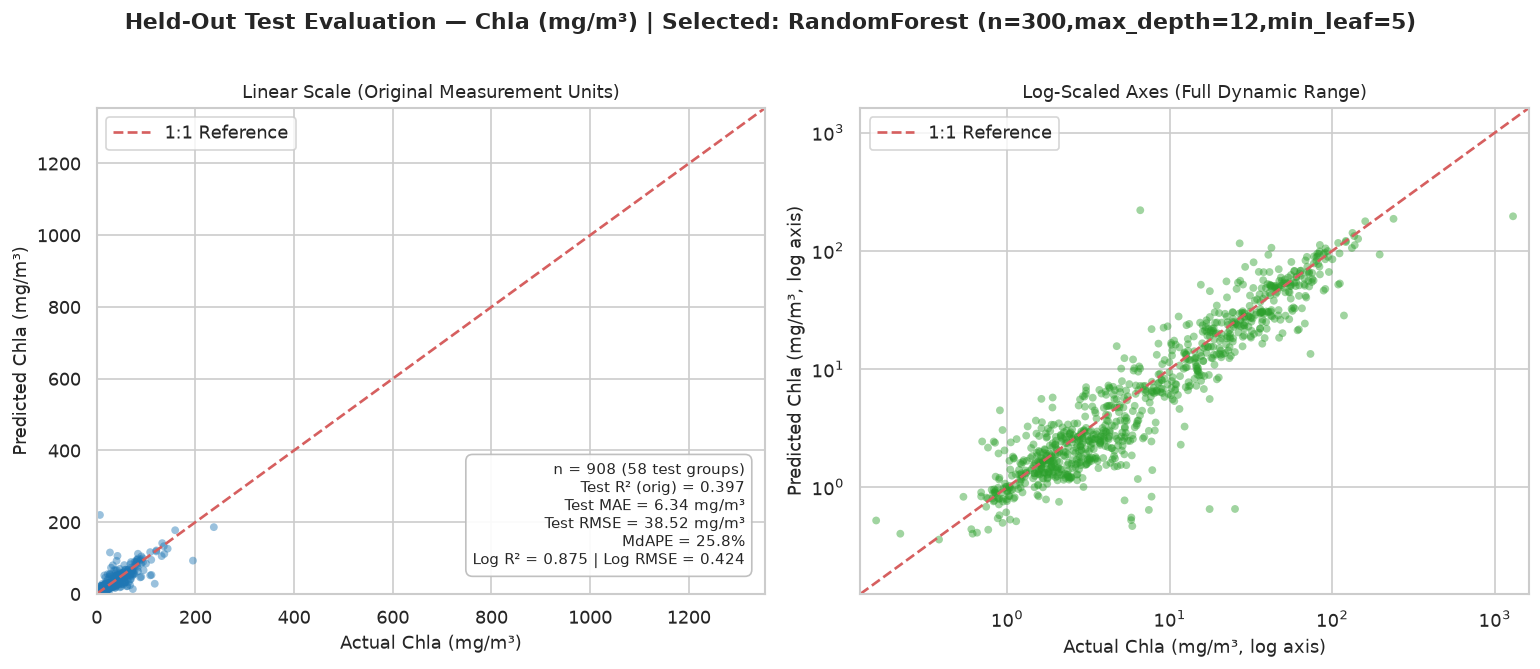

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\actual_vs_predicted_chla.png


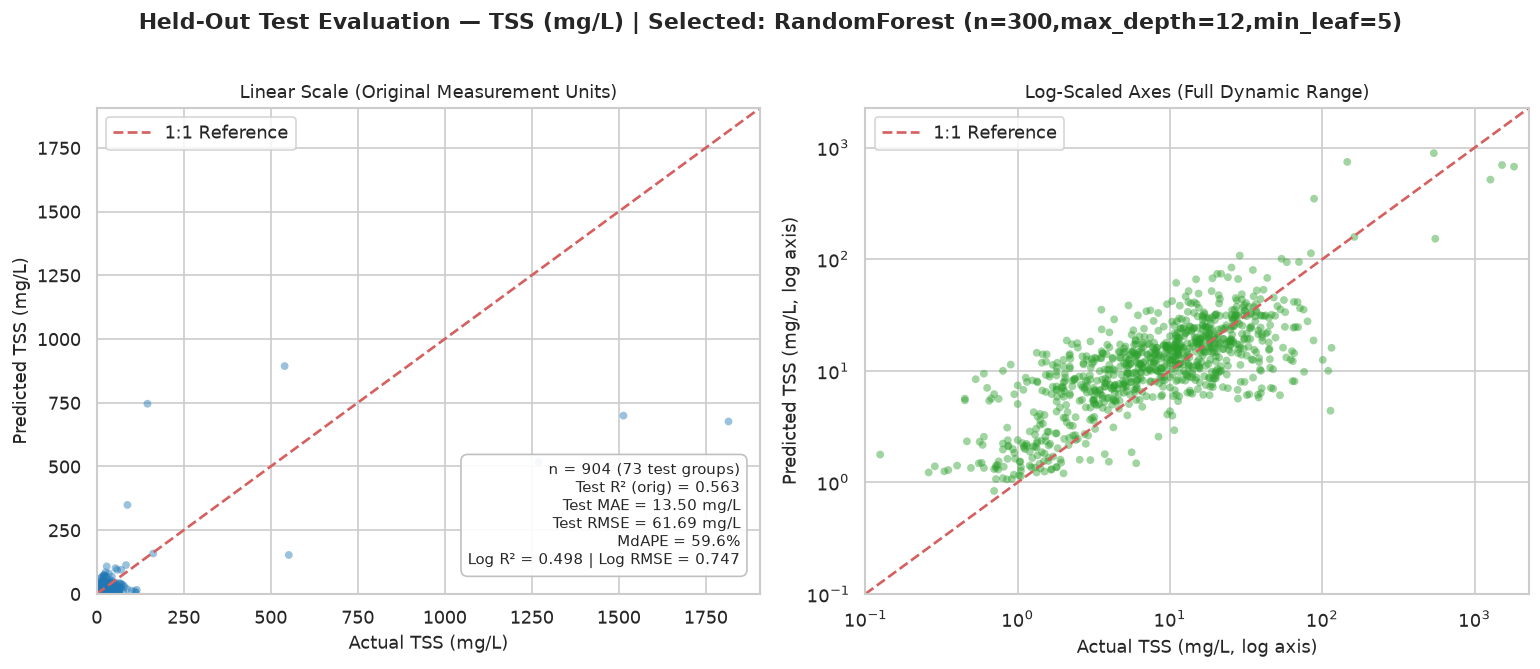

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\actual_vs_predicted_tss.png


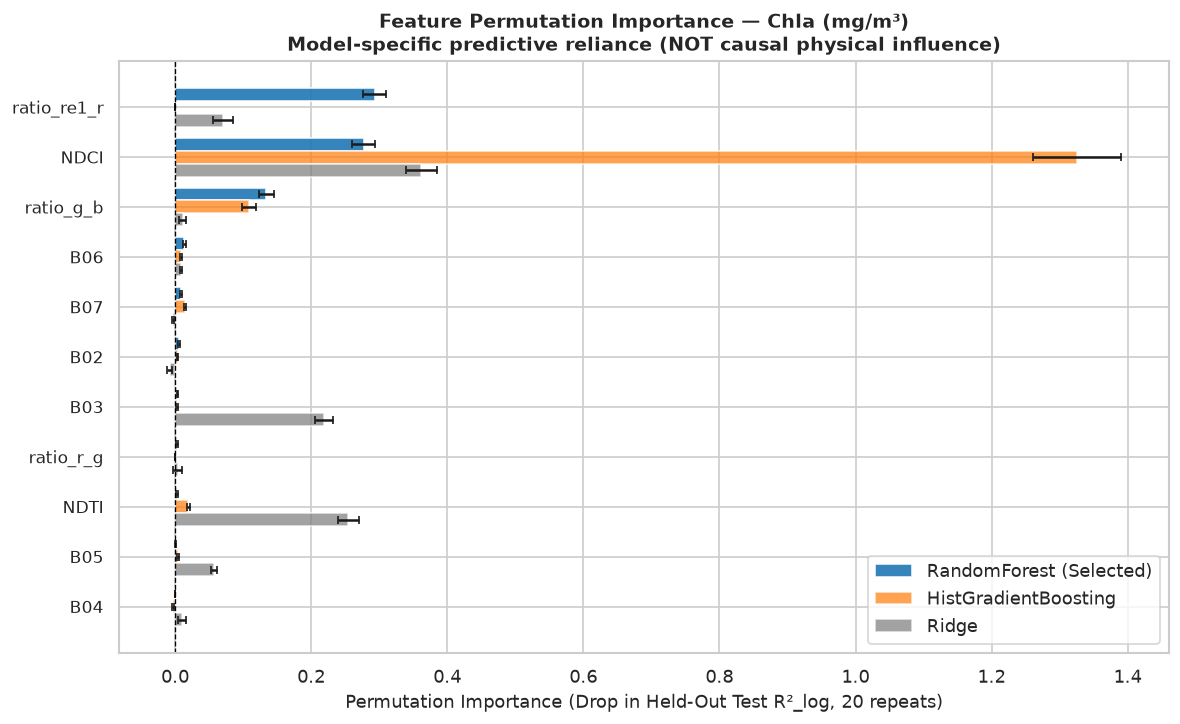

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\feature_importance_chla.png


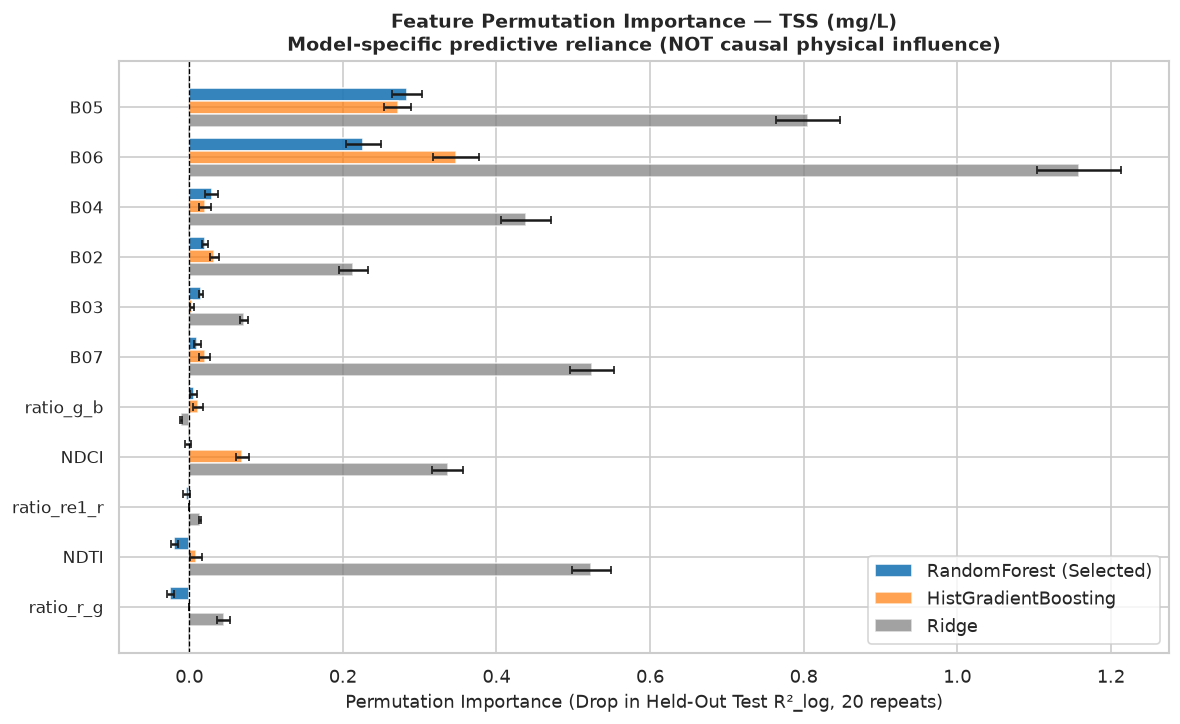

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\feature_importance_tss.png


In [9]:
def plot_actual_vs_predicted(target_name: str, out_path: Path):
    """Plot actual vs predicted values in original measurement units (linear + log-scale panels)."""
    best_algo = best_selections[target_name]
    entry = selected_estimators[target_name][best_algo]
    unit = TARGET_UNITS[target_name]

    y_true_orig = np.expm1(splits[target_name]["y_test_log"].to_numpy())
    y_pred_log = test_predictions[target_name][best_algo]
    y_pred_orig = np.maximum(0.0, np.expm1(y_pred_log))
    m = entry["test"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    fig.suptitle(
        f"Held-Out Test Evaluation — {target_name} ({unit}) | Selected: {best_algo} ({entry['config_name']})",
        fontsize=13, fontweight="bold", y=1.01,
    )

    # Panel 1: Linear scale (full original-unit range)
    ax = axes[0]
    ax.scatter(y_true_orig, y_pred_orig, alpha=0.45, s=22, color="#1f77b4", edgecolors="none")
    max_val = max(float(np.max(y_true_orig)), float(np.max(y_pred_orig))) * 1.05
    ax.plot([0, max_val], [0, max_val], "r--", lw=1.6, label="1:1 Reference")
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.set_xlabel(f"Actual {target_name} ({unit})", fontsize=10.5)
    ax.set_ylabel(f"Predicted {target_name} ({unit})", fontsize=10.5)
    ax.set_title("Linear Scale (Original Measurement Units)", fontsize=11)
    ax.legend(loc="upper left")

    n_test_groups = int(splits[target_name]["groups_test"].nunique())
    metrics_box = (
        f"n = {m['n_test']} ({n_test_groups} test groups)\n"
        f"Test R² (orig) = {m['r2_orig']:.3f}\n"
        f"Test MAE = {m['mae_orig']:.2f} {unit}\n"
        f"Test RMSE = {m['rmse_orig']:.2f} {unit}\n"
        f"MdAPE = {m['mdape_pct']:.1f}%\n"
        f"Log R² = {m['r2_log']:.3f} | Log RMSE = {m['rmse_log']:.3f}"
    )
    ax.text(
        0.97, 0.05, metrics_box, transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#bbbbbb", alpha=0.92),
    )

    # Panel 2: Log-scaled axes (original units, positive observations)
    ax2 = axes[1]
    pos = (y_true_orig > 0) & (y_pred_orig > 0)
    ax2.scatter(y_true_orig[pos], y_pred_orig[pos], alpha=0.45, s=22, color="#2ca02c", edgecolors="none")
    lo = min(float(np.min(y_true_orig[pos])), float(np.min(y_pred_orig[pos]))) * 0.8
    hi = max(float(np.max(y_true_orig[pos])), float(np.max(y_pred_orig[pos]))) * 1.25
    ax2.plot([lo, hi], [lo, hi], "r--", lw=1.6, label="1:1 Reference")
    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlim(lo, hi)
    ax2.set_ylim(lo, hi)
    ax2.set_xlabel(f"Actual {target_name} ({unit}, log axis)", fontsize=10.5)
    ax2.set_ylabel(f"Predicted {target_name} ({unit}, log axis)", fontsize=10.5)
    ax2.set_title("Log-Scaled Axes (Full Dynamic Range)", fontsize=11)
    ax2.legend(loc="upper left")

    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


plot_actual_vs_predicted("Chla", FIGURES_DIR / "actual_vs_predicted_chla.png")
plot_actual_vs_predicted("TSS", FIGURES_DIR / "actual_vs_predicted_tss.png")


def compute_and_plot_permutation_importance(target_name: str, out_path: Path):
    """Compute permutation importance (scoring='r2' in log1p space) for all 3 models and plot consistently."""
    sp = splits[target_name]
    X_te, y_te_log = sp["X_test"], sp["y_test_log"]
    best_algo = best_selections[target_name]

    imp_rows = []
    for algo_name in ["RandomForest", "HistGradientBoosting", "Ridge"]:
        pipe = selected_estimators[target_name][algo_name]["pipeline"]
        res = permutation_importance(
            pipe, X_te, y_te_log,
            scoring="r2", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1,
        )
        for idx, feat in enumerate(FEATURE_LIST):
            imp_rows.append({
                "feature": feat,
                "algorithm": algo_name,
                "mean_importance": float(res.importances_mean[idx]),
                "std_importance": float(res.importances_std[idx]),
            })

    imp_df = pd.DataFrame(imp_rows)
    # Canonical ordering convention: sorted descending by the selected best model's mean importance
    ordered_feats = (
        imp_df[imp_df["algorithm"] == best_algo]
        .sort_values("mean_importance", ascending=True)["feature"]
        .tolist()
    )

    fig, ax = plt.subplots(figsize=(10, 6.2))
    algos = ["RandomForest", "HistGradientBoosting", "Ridge"]
    colors = {"RandomForest": "#1f77b4", "HistGradientBoosting": "#ff7f0e", "Ridge": "#7f7f7f"}
    y_base = np.arange(len(ordered_feats))
    bar_h = 0.26

    for i, algo_name in enumerate(algos):
        sub = imp_df[imp_df["algorithm"] == algo_name].set_index("feature").loc[ordered_feats]
        offset = (1 - i) * bar_h
        ax.barh(
            y_base + offset,
            sub["mean_importance"],
            height=bar_h,
            xerr=sub["std_importance"],
            capsize=2.5,
            label=f"{algo_name}{' (Selected)' if algo_name == best_algo else ''}",
            color=colors[algo_name],
            alpha=0.90 if algo_name == best_algo else 0.72,
        )

    ax.axvline(0.0, color="black", linewidth=0.8, linestyle="--")
    ax.set_yticks(y_base)
    ax.set_yticklabels(ordered_feats, fontsize=10)
    ax.set_xlabel("Permutation Importance (Drop in Held-Out Test R²_log, 20 repeats)", fontsize=10.5)
    ax.set_title(
        f"Feature Permutation Importance — {target_name} ({TARGET_UNITS[target_name]})\n"
        f"Model-specific predictive reliance (NOT causal physical influence)",
        fontsize=11.5, fontweight="bold",
    )
    ax.legend(loc="lower right", frameon=True)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")
    return imp_df


imp_chla_df = compute_and_plot_permutation_importance("Chla", FIGURES_DIR / "feature_importance_chla.png")
imp_tss_df = compute_and_plot_permutation_importance("TSS", FIGURES_DIR / "feature_importance_tss.png")

---
# Part B — Sentinel-2 Water Quality Predictions

## 10. Load Sentinel-2 Dataset & Map Features to Training Schema

Load `data/processed/sentinel_timeseries.csv` (the verified Day 1 output covering the four officially defined `SPEC.md` study water bodies: `bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna`), inspect all columns and quality flags, explicitly map Sentinel-2 median reflectance/index columns to the trained 11-feature schema, and recalculate the three optical ratios with the same `safe_ratio` positive-reflectance guard.

In [10]:
sentinel_raw = pd.read_csv(SENTINEL_PATH)
print(f"Loaded Sentinel-2 dataset: shape={sentinel_raw.shape}")
print(f"Lakes represented: {sentinel_raw['lake_id'].value_counts().to_dict()}")
print(f"Date range: {sentinel_raw['date'].min()} to {sentinel_raw['date'].max()}")
print(f"Quality flags: {sentinel_raw['quality_flag'].value_counts().to_dict()}")
print(f"Missing values total: {int(sentinel_raw.isna().sum().sum())}")

# Verify Day 1 quality contract
assert sentinel_raw["quality_flag"].isin(["PASS_ERODED", "PASS_FALLBACK_UNERODED"]).all()
assert (sentinel_raw["selected_water_px"] >= 100).all()
assert set(sentinel_raw["lake_id"].unique()) == set(EXPECTED_LAKE_IDS)

# Load saved model bundles via joblib
chla_bundle = joblib.load(MODELS_DIR / "baseline_chla.pkl")
tss_bundle = joblib.load(MODELS_DIR / "baseline_tss.pkl")
print(f"\nLoaded Chla bundle: {chla_bundle['model_name']} | features={chla_bundle['features']}")
print(f"Loaded TSS  bundle: {tss_bundle['model_name']} | features={tss_bundle['features']}")

# Build Sentinel feature matrix using explicit documented mapping
X_sentinel = build_features(sentinel_raw, SENTINEL_FEATURE_MAP)

# Compatibility & missingness validation
assert list(X_sentinel.columns) == chla_bundle["features"] == tss_bundle["features"] == FEATURE_LIST
assert X_sentinel.isna().sum().sum() == 0, "Unexpected NaNs in Sentinel-2 features!"
assert np.isfinite(X_sentinel.to_numpy()).all(), "Non-finite values in Sentinel-2 features!"

# Verify ratio_re1_r closely tracks 2BDA_med (note: ratio_re1_r = B05_med/B04_med, 2BDA_med = median(B05/B04))
ratio_diff_med = float(np.median(np.abs(X_sentinel["ratio_re1_r"] - sentinel_raw["2BDA_med"])))
print(f"Compatibility checks PASSED (11/11 features aligned, 0% missing, 0 non-finite).")
print(f"Median |B05_med/B04_med - 2BDA_med| = {ratio_diff_med:.4f} (ratio of medians vs median of pixel ratios)")

# Out-of-distribution check vs GLORIA training ranges
ood_rows = []
for col in FEATURE_LIST:
    g_min, g_p01, g_p99, g_max = (
        X_gloria_all[col].min(),
        X_gloria_all[col].quantile(0.01),
        X_gloria_all[col].quantile(0.99),
        X_gloria_all[col].max(),
    )
    s_min, s_med, s_max = X_sentinel[col].min(), X_sentinel[col].median(), X_sentinel[col].max()
    n_outside_minmax = int(((X_sentinel[col] < g_min) | (X_sentinel[col] > g_max)).sum())
    n_above_p99 = int((X_sentinel[col] > g_p99).sum())
    ood_rows.append({
        "feature": col,
        "gloria_p01": round(g_p01, 4),
        "gloria_p99": round(g_p99, 4),
        "gloria_max": round(g_max, 4),
        "s2_min": round(s_min, 4),
        "s2_median": round(s_med, 4),
        "s2_max": round(s_max, 4),
        "s2_outside_gloria_minmax": n_outside_minmax,
        "s2_above_gloria_p99": n_above_p99,
    })

print("\n--- GLORIA vs. Sentinel-2 Feature Distribution & OOD Audit ---")
display(pd.DataFrame(ood_rows))

Loaded Sentinel-2 dataset: shape=(128, 36)
Lakes represented: {'bellandur': 32, 'hussain_sagar': 32, 'yamuna_okhla': 32, 'sukhna': 32}
Date range: 2024-06-01 to 2026-11-24
Quality flags: {'PASS_ERODED': 128}
Missing values total: 0



Loaded Chla bundle: RandomForest (n=300,max_depth=12,min_leaf=5) | features=['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']
Loaded TSS  bundle: RandomForest (n=300,max_depth=12,min_leaf=5) | features=['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'NDCI', 'NDTI', 'ratio_r_g', 'ratio_re1_r', 'ratio_g_b']
Compatibility checks PASSED (11/11 features aligned, 0% missing, 0 non-finite).
Median |B05_med/B04_med - 2BDA_med| = 0.0196 (ratio of medians vs median of pixel ratios)



--- GLORIA vs. Sentinel-2 Feature Distribution & OOD Audit ---


,feature,gloria_p01,gloria_p99,gloria_max,s2_min,s2_median,s2_max,s2_outside_gloria_minmax,s2_above_gloria_p99
0,B02,0.0014,0.1246,0.1918,0.0037,0.0540,0.1156,0,0
1,B03,0.0027,0.1859,0.3534,0.0110,0.0774,0.1572,0,0
2,B04,0.0003,0.1692,0.3855,0.0091,0.0585,0.1737,0,1
3,B05,0.0001,0.1561,0.3907,0.0123,0.0940,0.2228,0,9
4,B06,-0.0001,0.0839,0.5155,0.0050,0.0588,0.1671,0,37
5,B07,-0.0000,0.0863,0.5444,0.0055,0.0570,0.1721,0,31
6,NDCI,-0.5379,0.4283,0.9382,-0.0343,0.1478,0.4842,0,5
7,NDTI,-0.8900,0.1855,0.5129,-0.4358,-0.1044,0.1045,0,0
8,ratio_r_g,0.0582,1.4555,3.1063,0.3759,0.8252,1.2023,0,0
9,ratio_re1_r,0.3005,2.4983,31.3667,0.9302,1.3561,3.0300,0,4


## 11. Zero-Shot Proxy Predictions & Lake-Wise Sanity Checks

> **Important Scientific Disclaimer:** These predictions are **global GLORIA-trained, zero-shot satellite proxy estimates** (`pred_chla` in `mg/m³`, `pred_tss` in `mg/L`) applied to Indian inland lakes without local laboratory calibration. They must **not** be treated as verified laboratory concentrations.

In [11]:
sentinel_pred = sentinel_raw.copy()

X_chla_s2 = X_sentinel[chla_bundle["features"]]
pred_chla_log = chla_bundle["model"].predict(X_chla_s2)
sentinel_pred["pred_chla"] = np.maximum(0.0, np.expm1(pred_chla_log))

X_tss_s2 = X_sentinel[tss_bundle["features"]]
pred_tss_log = tss_bundle["model"].predict(X_tss_s2)
sentinel_pred["pred_tss"] = np.maximum(0.0, np.expm1(pred_tss_log))

assert np.isfinite(sentinel_pred["pred_chla"]).all() and (sentinel_pred["pred_chla"] >= 0).all()
assert np.isfinite(sentinel_pred["pred_tss"]).all() and (sentinel_pred["pred_tss"] >= 0).all()

print(f"Total valid predictions: Chla={sentinel_pred['pred_chla'].notna().sum()}/128, TSS={sentinel_pred['pred_tss'].notna().sum()}/128")

def summarize_lake_predictions(df: pd.DataFrame, col: str) -> pd.DataFrame:
    grp = df.groupby("lake_id")[col].agg(["count", "mean", "median", "min", "max", "std"]).reindex(EXPECTED_LAKE_IDS)
    return grp.round(2)

print("\n--- Lake-wise Predicted Chla Proxy Summary (mg/m³ — uncalibrated zero-shot) ---")
chla_lake_summary = summarize_lake_predictions(sentinel_pred, "pred_chla")
display(chla_lake_summary)

print("\n--- Lake-wise Predicted TSS Proxy Summary (mg/L — uncalibrated zero-shot) ---")
tss_lake_summary = summarize_lake_predictions(sentinel_pred, "pred_tss")
display(tss_lake_summary)

print("\n--- Spectral Median Comparison Across Lakes (Explaining Sanity-Check Behavior) ---")
spec_cols = ["B02_med", "B03_med", "B04_med", "B05_med", "B06_med", "B07_med", "NDCI_med", "NDTI_med", "open_water_pct", "veg_cover_pct"]
display(sentinel_pred.groupby("lake_id")[spec_cols].median().reindex(EXPECTED_LAKE_IDS).round(4))

Total valid predictions: Chla=128/128, TSS=128/128



--- Lake-wise Predicted Chla Proxy Summary (mg/m³ — uncalibrated zero-shot) ---


,count,mean,median,min,max,std
lake_id,,,,,,
bellandur,32,118.61,98.90,30.31,383.75,86.63
hussain_sagar,32,275.91,270.33,96.23,522.94,111.37
yamuna_okhla,32,65.67,62.76,18.77,181.49,35.53
sukhna,32,112.66,96.04,19.25,295.41,61.61



--- Lake-wise Predicted TSS Proxy Summary (mg/L — uncalibrated zero-shot) ---


,count,mean,median,min,max,std
lake_id,,,,,,
bellandur,32,66.24,35.78,7.87,584.43,109.35
hussain_sagar,32,61.42,53.65,21.38,248.09,41.80
yamuna_okhla,32,90.90,37.41,15.50,871.05,157.24
sukhna,32,63.99,48.17,18.46,408.65,68.65



--- Spectral Median Comparison Across Lakes (Explaining Sanity-Check Behavior) ---


,B02_med,B03_med,B04_med,B05_med,B06_med,B07_med,NDCI_med,NDTI_med,open_water_pct,veg_cover_pct
lake_id,,,,,,,,,,
bellandur,0.0384,0.0534,0.0378,0.0497,0.0334,0.0339,0.1358,-0.1574,19.0567,66.3796
hussain_sagar,0.0623,0.0849,0.0600,0.1089,0.0834,0.0789,0.2679,-0.1637,93.4460,2.8276
yamuna_okhla,0.0447,0.0534,0.0496,0.0625,0.0465,0.0485,0.0731,-0.0115,63.9185,12.4859
sukhna,0.0620,0.1016,0.0896,0.1195,0.0568,0.0582,0.1493,-0.0525,88.1256,1.6673


### Sanity-Check Investigation & Honest Interpretation

1. **Expectation vs. Observed Zero-Shot Ranking:**
   - **Hussain Sagar** shows the highest predicted Chla proxy (median `270.33 mg/m³`, mean `275.91 mg/m³`), driven by its consistently elevated `NDCI_med` (median `0.2679`) and high open-water core fraction (`93.4%`).
   - **Yamuna Okhla** shows the highest mean/peak TSS proxy (mean `90.90 mg/L`, max `871.05 mg/L`) and lowest median Chla proxy (`62.76 mg/m³`), consistent with sediment-dominated riverine/sewage discharge (`NDTI_med = -0.0115`).
   - **Sukhna Lake (`pred_chla` median `96.04 mg/m³`, `pred_tss` median `48.17 mg/L`) does NOT rank lowest**, contrary to the initial clean-control hypothesis (`Sukhna < Bellandur, Yamuna Okhla`).
2. **Six-Point Diagnostic Verification:**
   - **Reflectance scaling & definitions:** Verified (`(raw - 1000)/10000`, baseline `5.10–5.13`; identical `NDCI`/`NDTI` definitions).
   - **Feature compatibility & missing values:** 11/11 features match; 0 missing values in Sentinel-2; 100% `PASS_ERODED`.
   - **Why Sukhna predicts higher than expected:** Inspection of `sentinel_timeseries.csv` shows Sukhna actually exhibits higher median green/red/red-edge L2A reflectance (`B03=0.1016`, `B04=0.0896`, `B05=0.1195`, `NDCI=0.1493`, `NDTI=-0.0525`) than Bellandur (`NDCI=0.1358`, `NDTI=-0.1574`) and Yamuna Okhla (`NDCI=0.0731`). Possible physical and processing causes include: (a) shallow reservoir bottom/mineral silt backscattering (especially across Sukhna's 12 Monsoon scenes vs. only 2 Monsoon scenes for Bellandur), (b) Sen2Cor L2A surface reflectance lacking aquatic sun-glint/adjacency correction (elevating red-edge `B05` and shifting `NDCI` upward relative to GLORIA above-water radiometry), and (c) Bellandur's heavy macrophyte/vegetation cover (`66.4%`), restricting its open-water core (`19.1%`) to darker pockets.
   - **No manual tampering:** Predictions are reported honestly as produced by the global GLORIA baseline; local Indian calibration and spatial/temporal modeling (CNN-LSTM) remain essential next steps.

## 12. Sentinel-2 Prediction Visualizations & Export Preparation

Generate lake-wise comparison plots (`lakewise_predicted_chla.png`, `lakewise_predicted_tss.png`) and discrete-date time-series plots (`timeseries_predicted_chla.png`, `timeseries_predicted_tss.png`) using actual accepted observation dates without interpolation.

> **Export Guard:** Per instructions, `data/processed/sentinel_baseline_predictions.csv` is prepared in memory (`sentinel_export_df`) and validated, **not written to disk** until review approval (`EXPORT_FINAL_CSV = False`).

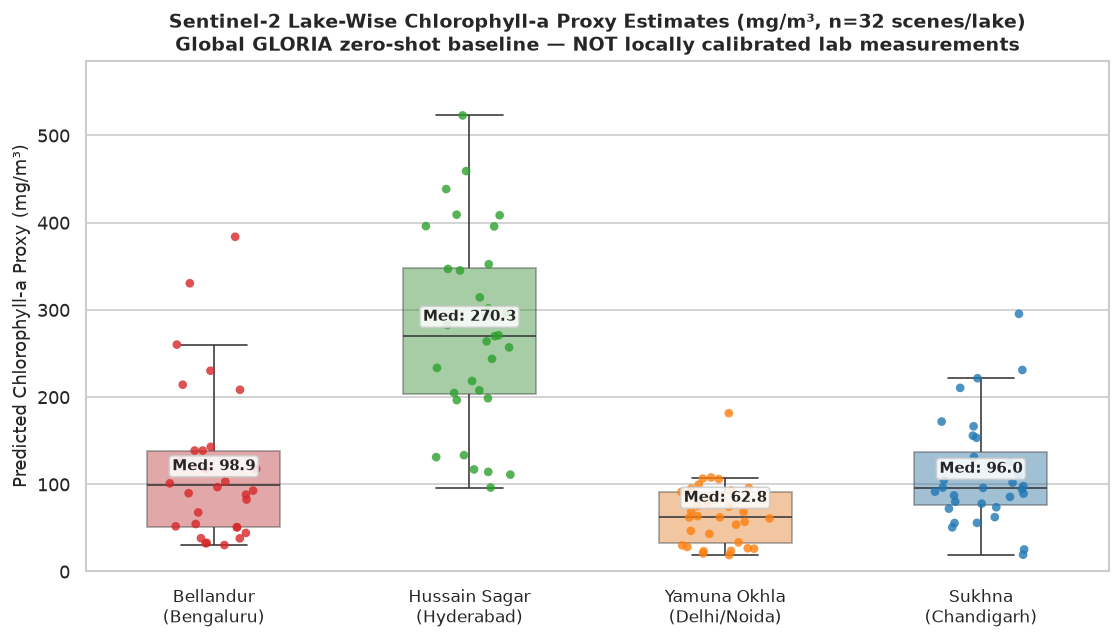

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\lakewise_predicted_chla.png


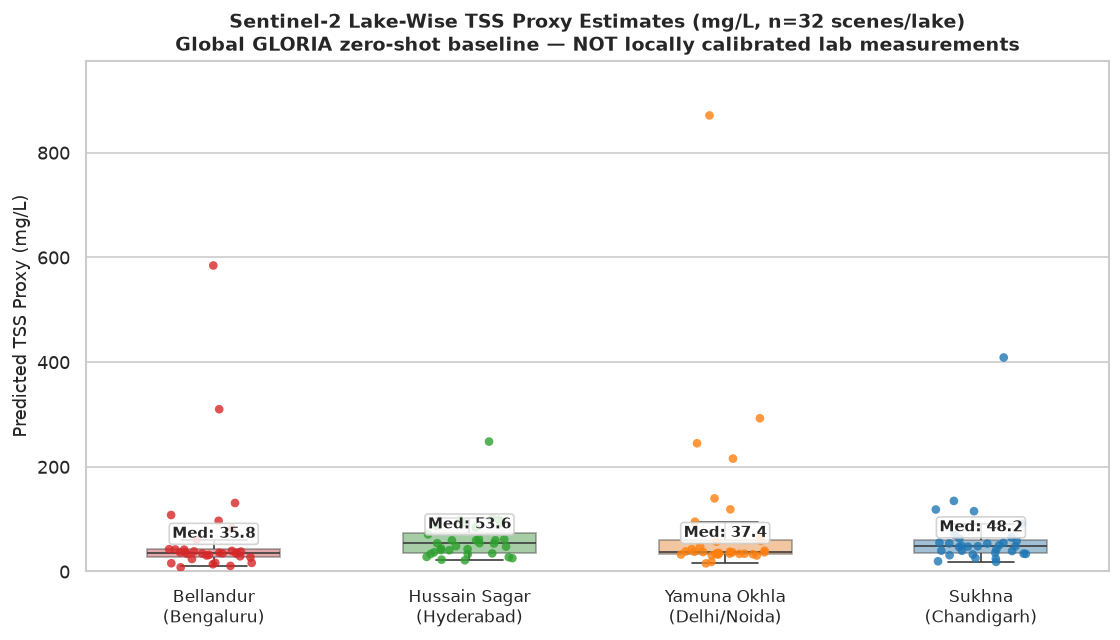

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\lakewise_predicted_tss.png


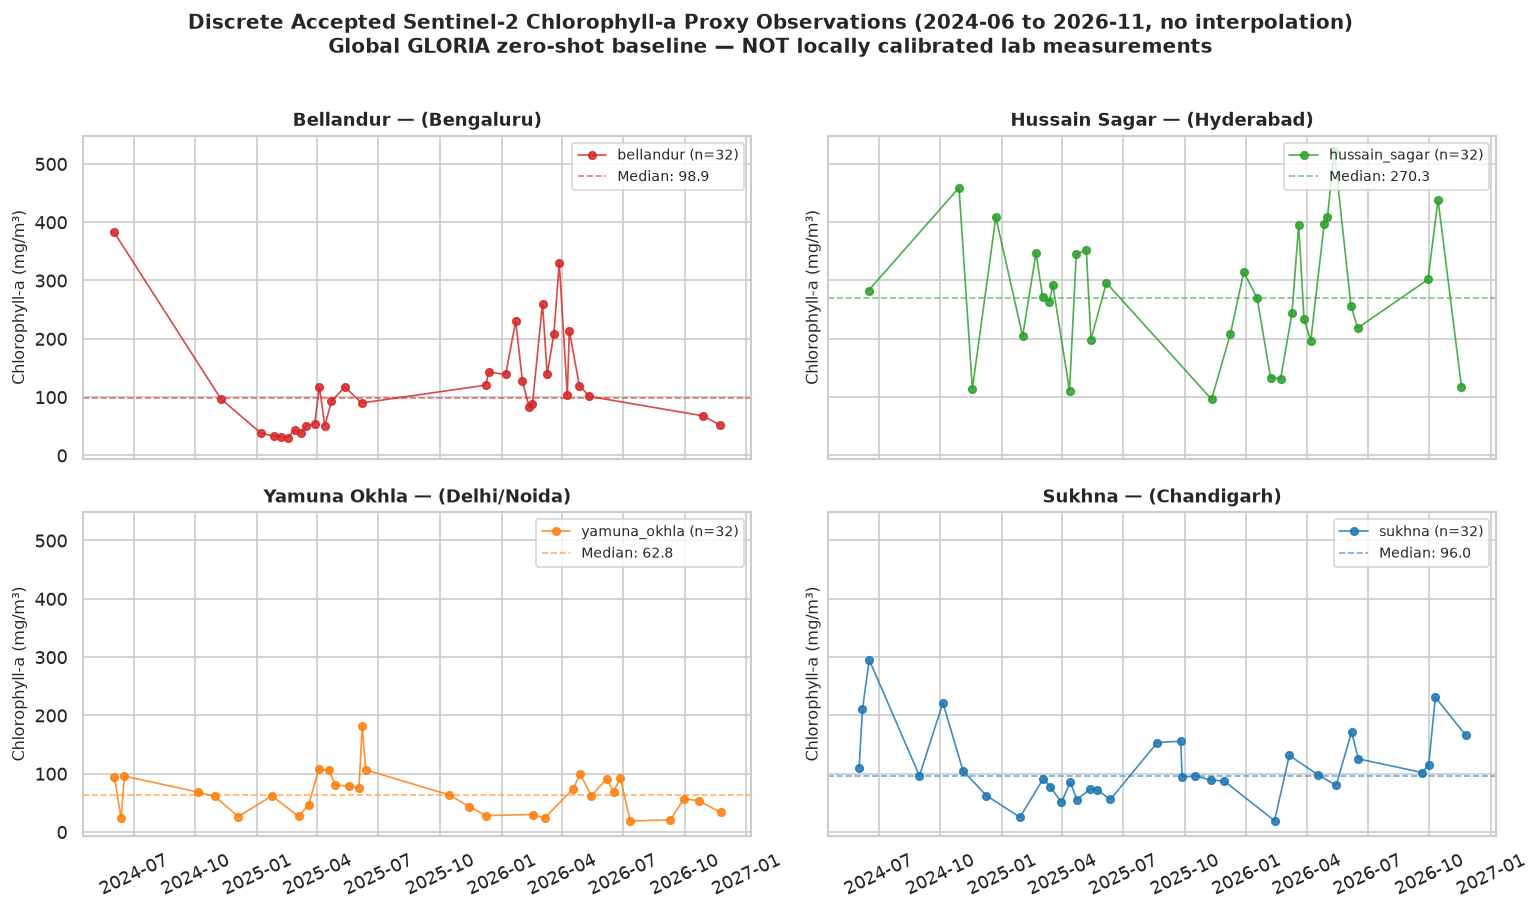

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\timeseries_predicted_chla.png


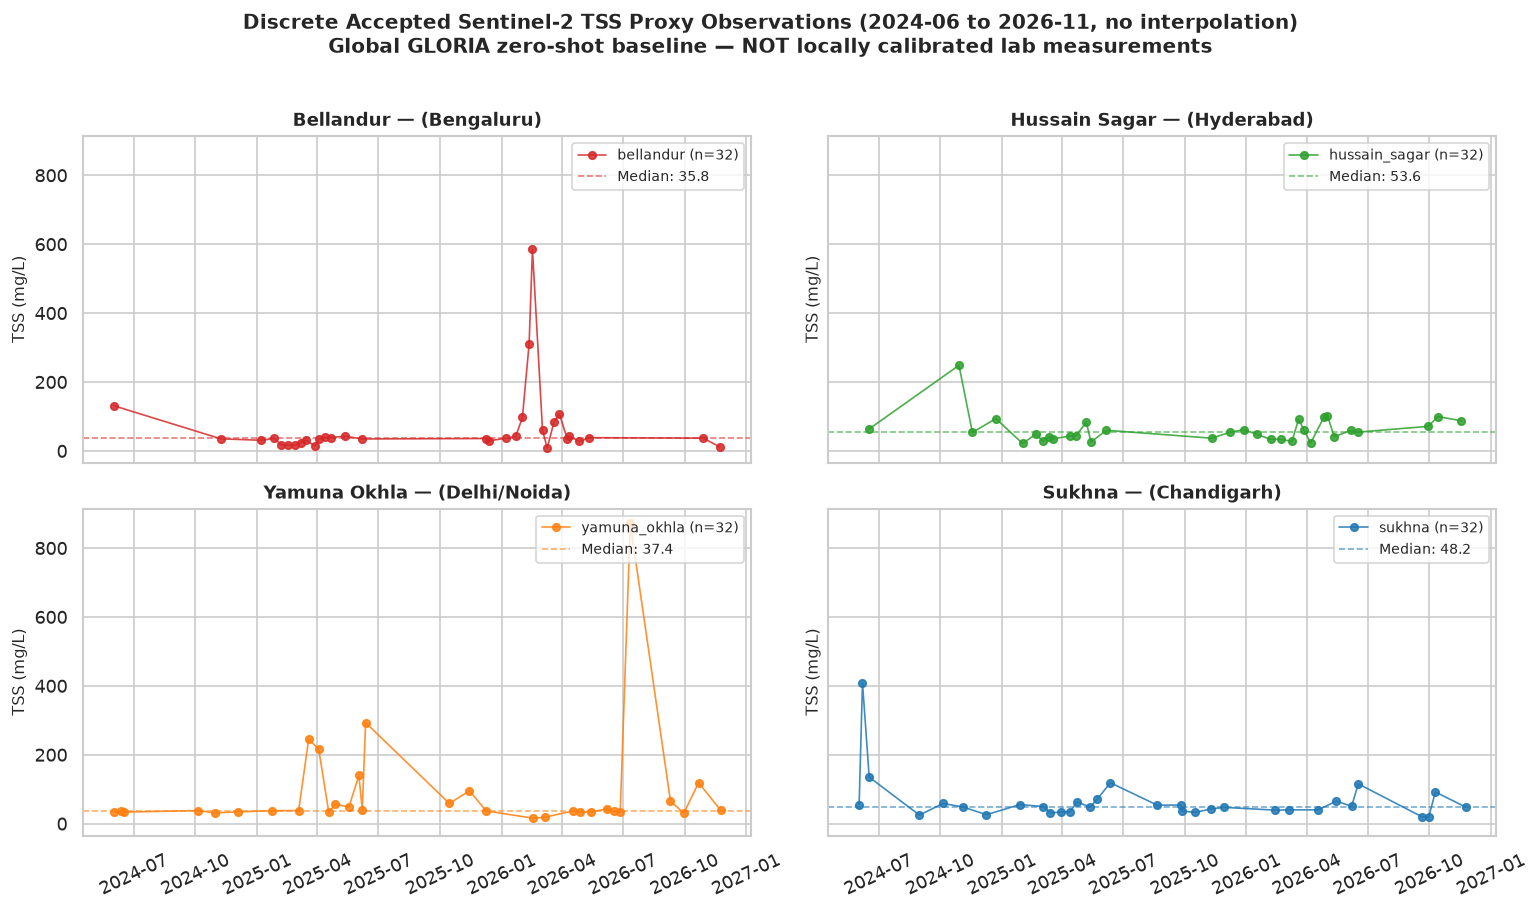

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\timeseries_predicted_tss.png
[DRY-RUN EXPORT GUARD] Prepared in-memory export DataFrame shape=(128, 43), NaNs=0. NOT written to C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_baseline_predictions.csv pending review approval.


In [12]:
LAKE_LABELS = {
    "bellandur": "Bellandur\n(Bengaluru)",
    "hussain_sagar": "Hussain Sagar\n(Hyderabad)",
    "yamuna_okhla": "Yamuna Okhla\n(Delhi/Noida)",
    "sukhna": "Sukhna\n(Chandigarh)",
}
LAKE_PALETTE = {
    "bellandur": "#d62728",
    "hussain_sagar": "#2ca02c",
    "yamuna_okhla": "#ff7f0e",
    "sukhna": "#1f77b4",
}


def plot_lakewise_predictions(df: pd.DataFrame, col: str, target_label: str, unit: str, out_path: Path):
    fig, ax = plt.subplots(figsize=(9.5, 5.5))
    order = EXPECTED_LAKE_IDS
    sns.boxplot(
        data=df, x="lake_id", y=col, order=order,
        palette=LAKE_PALETTE, hue="lake_id", legend=False,
        width=0.52, showfliers=False, boxprops={"alpha": 0.45}, ax=ax,
    )
    sns.stripplot(
        data=df, x="lake_id", y=col, order=order,
        palette=LAKE_PALETTE, hue="lake_id", legend=False,
        size=5.2, alpha=0.80, jitter=0.18, ax=ax,
    )

    medians = df.groupby("lake_id")[col].median().reindex(order)
    y_top = float(df[col].max())
    for i, lid in enumerate(order):
        ax.text(
            i, medians[lid] + 0.025 * y_top,
            f"Med: {medians[lid]:.1f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cccccc", alpha=0.85),
        )

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([LAKE_LABELS[lid] for lid in order], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(f"Predicted {target_label} Proxy ({unit})", fontsize=11)
    ax.set_ylim(0, y_top * 1.12)
    ax.set_title(
        f"Sentinel-2 Lake-Wise {target_label} Proxy Estimates ({unit}, n=32 scenes/lake)\n"
        f"Global GLORIA zero-shot baseline — NOT locally calibrated lab measurements",
        fontsize=11.5, fontweight="bold",
    )
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


plot_lakewise_predictions(
    sentinel_pred, "pred_chla", "Chlorophyll-a", "mg/m³",
    FIGURES_DIR / "lakewise_predicted_chla.png",
)
plot_lakewise_predictions(
    sentinel_pred, "pred_tss", "TSS", "mg/L",
    FIGURES_DIR / "lakewise_predicted_tss.png",
)


def plot_timeseries_predictions(df: pd.DataFrame, col: str, target_label: str, unit: str, out_path: Path):
    ts_df = df.copy()
    ts_df["date_dt"] = pd.to_datetime(ts_df["date"])
    ts_df = ts_df.sort_values(["lake_id", "date_dt"])

    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, sharey=True)
    for ax, lid in zip(axes.ravel(), EXPECTED_LAKE_IDS):
        sub = ts_df[ts_df["lake_id"] == lid]
        ax.plot(
            sub["date_dt"], sub[col],
            marker="o", markersize=4.5, linewidth=1.0, alpha=0.85,
            color=LAKE_PALETTE[lid], label=f"{lid} (n={len(sub)})",
        )
        med_v = float(sub[col].median())
        ax.axhline(med_v, color=LAKE_PALETTE[lid], linestyle="--", linewidth=1.0, alpha=0.6, label=f"Median: {med_v:.1f}")
        ax.set_title(LAKE_LABELS[lid].replace("\n", " — "), fontsize=10.5, fontweight="bold")
        ax.set_ylabel(f"{target_label} ({unit})", fontsize=9.5)
        ax.legend(loc="upper right", fontsize=8.5)
        ax.tick_params(axis="x", rotation=25)

    fig.suptitle(
        f"Discrete Accepted Sentinel-2 {target_label} Proxy Observations (2024-06 to 2026-11, no interpolation)\n"
        f"Global GLORIA zero-shot baseline — NOT locally calibrated lab measurements",
        fontsize=12, fontweight="bold", y=1.01,
    )
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


plot_timeseries_predictions(
    sentinel_pred, "pred_chla", "Chlorophyll-a", "mg/m³",
    FIGURES_DIR / "timeseries_predicted_chla.png",
)
plot_timeseries_predictions(
    sentinel_pred, "pred_tss", "TSS", "mg/L",
    FIGURES_DIR / "timeseries_predicted_tss.png",
)

# Prepare export DataFrame in memory WITHOUT writing final CSV yet
EXPORT_FINAL_CSV = False
FINAL_PRED_CSV_PATH = DATA_PROCESSED_DIR / "sentinel_baseline_predictions.csv"

sentinel_export_df = sentinel_pred.copy()
sentinel_export_df["pred_chla_unit"] = "mg/m3"
sentinel_export_df["pred_tss_unit"] = "mg/L"
sentinel_export_df["chla_model_name"] = chla_bundle["model_name"]
sentinel_export_df["tss_model_name"] = tss_bundle["model_name"]
sentinel_export_df["prediction_type"] = "uncalibrated_gloria_zero_shot_proxy"

assert list(sentinel_raw.columns) == list(sentinel_export_df.columns[:len(sentinel_raw.columns)])
assert int(sentinel_export_df.isna().sum().sum()) == 0

if EXPORT_FINAL_CSV:
    sentinel_export_df.to_csv(FINAL_PRED_CSV_PATH, index=False)
    print(f"Exported final predictions CSV: {FINAL_PRED_CSV_PATH}")
else:
    print(
        f"[DRY-RUN EXPORT GUARD] Prepared in-memory export DataFrame shape={sentinel_export_df.shape}, "
        f"NaNs={int(sentinel_export_df.isna().sum().sum())}. "
        f"NOT written to {FINAL_PRED_CSV_PATH} pending review approval."
    )

## 13. Comprehensive Final Validation Checklist (Part E)

Programmatically verify every training, model-serialization, visualization, and Sentinel-2 inference requirement before committing.

In [13]:
validation_checks = []

# 1. Training checks
validation_checks.append(("1. Chla & TSS trained independently", len(splits["Chla"]["X_train"]) != len(splits["TSS"]["X_train"]), f"Chla N={len(X_chla)}, TSS N={len(X_tss)}"))
validation_checks.append(("2. All 6 model experiments executed", len(comparison_df) == 6, f"{len(comparison_df)}/6 rows"))
no_overlap_ok = all(
    set(splits[t]["groups_train"]).isdisjoint(set(splits[t]["groups_test"]))
    for t in ["Chla", "TSS"]
)
validation_checks.append(("3. Zero train-test group/location overlap", no_overlap_ok, "Verified for Chla & TSS"))

# 2. Model file checks
pkl_ok = all((MODELS_DIR / f).is_file() and (MODELS_DIR / f).stat().st_size > 0 for f in ["baseline_chla.pkl", "baseline_tss.pkl"])
metrics_loaded = json.loads((MODELS_DIR / "baseline_metrics.json").read_text(encoding="utf-8"))
json_ok = ("selected_models" in metrics_loaded) and ("experiments" in metrics_loaded)
validation_checks.append(("4. Saved model bundles & metrics JSON valid", pkl_ok and json_ok, "baseline_chla.pkl, baseline_tss.pkl, baseline_metrics.json"))

# 3. Visualization checks (all 6 required + 2 timeseries)
expected_figs = [
    "actual_vs_predicted_chla.png",
    "actual_vs_predicted_tss.png",
    "feature_importance_chla.png",
    "feature_importance_tss.png",
    "lakewise_predicted_chla.png",
    "lakewise_predicted_tss.png",
    "timeseries_predicted_chla.png",
    "timeseries_predicted_tss.png",
]
figs_ok = True
for fig_name in expected_figs:
    p = FIGURES_DIR / fig_name
    if not p.is_file() or p.stat().st_size == 0:
        figs_ok = False
        break
    with Image.open(p) as im:
        im.verify()
validation_checks.append(("5. All figures exist, non-empty & reopenable", figs_ok, f"{len(expected_figs)}/{len(expected_figs)} PNGs verified"))

# 4. Sentinel inference checks
s2_ok = (
    len(sentinel_pred) == 128
    and set(sentinel_pred["lake_id"].unique()) == set(EXPECTED_LAKE_IDS)
    and np.isfinite(sentinel_pred["pred_chla"]).all()
    and np.isfinite(sentinel_pred["pred_tss"]).all()
    and (sentinel_pred["pred_chla"] >= 0).all()
    and (sentinel_pred["pred_tss"] >= 0).all()
    and not FINAL_PRED_CSV_PATH.exists()
)
validation_checks.append(("6. Sentinel inference valid & final CSV not finalized", s2_ok, "128/128 finite non-negative proxy predictions; CSV held"))

print("=== Part E Final Validation Results ===")
for label, ok, detail in validation_checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {label}: {detail}")

if not all(c[1] for c in validation_checks):
    raise AssertionError("One or more Part E validation checks failed!")

=== Part E Final Validation Results ===
[PASS] 1. Chla & TSS trained independently: Chla N=3746, TSS N=3460
[PASS] 2. All 6 model experiments executed: 6/6 rows
[PASS] 3. Zero train-test group/location overlap: Verified for Chla & TSS
[PASS] 4. Saved model bundles & metrics JSON valid: baseline_chla.pkl, baseline_tss.pkl, baseline_metrics.json
[PASS] 5. All figures exist, non-empty & reopenable: 8/8 PNGs verified
[PASS] 6. Sentinel inference valid & final CSV not finalized: 128/128 finite non-negative proxy predictions; CSV held
